# Step 1: Import all libraries for the analysis

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

# Step 2: Read the dataset

In [77]:
hiv_data = pd.read_csv('Patient_Line_List.csv', on_bad_lines='warn' )
hiv_data

Skipping line 28806: expected 50 fields, saw 51

Skipping line 108334: expected 50 fields, saw 51

Skipping line 123869: expected 50 fields, saw 51
Skipping line 124078: expected 50 fields, saw 51

Skipping line 135334: expected 50 fields, saw 51
Skipping line 144897: expected 50 fields, saw 51
Skipping line 147181: expected 50 fields, saw 51

Skipping line 150104: expected 50 fields, saw 51
Skipping line 152210: expected 50 fields, saw 51
Skipping line 156684: expected 50 fields, saw 51

Skipping line 174668: expected 50 fields, saw 51
Skipping line 174670: expected 50 fields, saw 51

Skipping line 186459: expected 50 fields, saw 51

Skipping line 216171: expected 50 fields, saw 51
Skipping line 222666: expected 50 fields, saw 51

Skipping line 254576: expected 50 fields, saw 51
Skipping line 261663: expected 50 fields, saw 51

Skipping line 273738: expected 50 fields, saw 51

Skipping line 285500: expected 50 fields, saw 51

C:\Users\HP\AppData\Local\Temp\ipykernel_14528\349591560.py

,IP,State,LGA,Facility,DATIM Code,Sex,Patient_Id,Patient Identifier,Hospital Number,Date Of Birth,...,Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Patient Has Died,Patient Deceased Date,Patient Transferred Out,Transferred Out Date,Patient Transferred In,Transferred In Date,Unnamed: 49
0,CCFN,Imo,Owerri Municipal,im Imo Specialist Hospital- Owerri,tPCkzZPirjX,F,6837705,0015626,NaN,1978-01-01,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
1,CCFN,Imo,aboh mbaise,Aboh Mbaise General Hospital,qGQliH5UA4W,M,8712555,IMO94502801,03006,1989-04-05,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
2,CCFN,Imo,aboh mbaise,Aboh Mbaise General Hospital,qGQliH5UA4W,F,8712788,IMO94500062,NaN,1983-01-01,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
3,CCFN,Imo,Ohaji/Egbema,General Hospital Egbema,cXN58l7fdGH,M,4967789,01708,NaN,1975-01-01,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
4,CCFN,Enugu,Nsukka,en Bishop Shanahan Hospital- Nsukka,iIW3pyzPNlE,M,7953043,ENU1303291,0006163,1996-01-22,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298077,CCFN,Imo,Ohaji/Egbema,General Hospital Egbema,cXN58l7fdGH,F,18744491,7320,NaN,1996-08-07,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
298078,CCFN,Imo,Ohaji/Egbema,General Hospital Egbema,cXN58l7fdGH,F,18744492,7333,NaN,2000-09-15,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
298079,CCFN,Imo,Ohaji/Egbema,General Hospital Egbema,cXN58l7fdGH,F,18744493,7335,NaN,1991-10-24,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN
298080,CCFN,Imo,Ohaji/Egbema,General Hospital Egbema,cXN58l7fdGH,M,18744496,7330,NaN,1992-03-14,...,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,NaN


In [78]:
hiv_data.isnull().any()

IP                               False
State                            False
LGA                              False
Facility                         False
DATIM Code                       False
Sex                              False
Patient_Id                       False
Patient Identifier               False
Hospital Number                   True
Date Of Birth                    False
Age at ART Initiation            False
Current Age                      False
ART Start Date                   False
ART Start Date Source             True
Last Drug Pickup date             True
Last Drug Pickup date Q1          True
Last Drug Pickup date Q2          True
Last Drug Pickup date Q3          True
Last Drug Pickup date Q4          True
Last Regimen                      True
Last Clinic Visit Date            True
Days Of ARV Refill                True
Pregnancy Status                  True
Current Viral Load                True
Date Of Current Viral Load        True
Current Viral Load Q1    

In [79]:
hiv_data.isnull().sum()

IP                                    0
State                                 0
LGA                                   0
Facility                              0
DATIM Code                            0
Sex                                   0
Patient_Id                            0
Patient Identifier                    0
Hospital Number                   60481
Date Of Birth                         0
Age at ART Initiation                 0
Current Age                           0
ART Start Date                        0
ART Start Date Source            298082
Last Drug Pickup date             12990
Last Drug Pickup date Q1          17655
Last Drug Pickup date Q2          15413
Last Drug Pickup date Q3         298082
Last Drug Pickup date Q4         298082
Last Regimen                      20578
Last Clinic Visit Date            11869
Days Of ARV Refill                12990
Pregnancy Status                 258859
Current Viral Load                69274
Date Of Current Viral Load        69274


In [80]:
hiv_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298082 entries, 0 to 298081
Data columns (total 50 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   IP                             298082 non-null  object 
 1   State                          298082 non-null  object 
 2   LGA                            298082 non-null  object 
 3   Facility                       298082 non-null  object 
 4   DATIM Code                     298082 non-null  object 
 5   Sex                            298082 non-null  object 
 6   Patient_Id                     298082 non-null  int64  
 7   Patient Identifier             298082 non-null  object 
 8   Hospital Number                237601 non-null  object 
 9   Date Of Birth                  298082 non-null  object 
 10  Age at ART Initiation          298082 non-null  int64  
 11  Current Age                    298082 non-null  int64  
 12  ART Start Date                

In [81]:
hiv_data.describe()

,Patient_Id,Age at ART Initiation,Current Age,ART Start Date Source,Last Drug Pickup date Q3,Last Drug Pickup date Q4,Days Of ARV Refill,Current Viral Load,Current Viral Load Q1,Current Viral Load Q2,Current Viral Load Q3,Date Of Current Viral Load Q3,Current Viral Load Q4,Date Of Current Viral Load Q4,Current Status Q3 (28 Days),Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Unnamed: 49
count,2.980820e+05,298082.000000,298082.000000,0.0,0.0,0.0,285092.000000,2.288080e+05,2.130660e+05,2.157940e+05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,9.937044e+06,33.716555,38.935061,NaN,NaN,NaN,112.310093,1.147475e+04,4.424017e+03,4.404810e+03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,4.583873e+06,12.077400,12.729094,NaN,NaN,NaN,48.196224,2.093920e+06,2.401645e+05,2.347494e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,3.012330e+05,-968.000000,0.000000,NaN,NaN,NaN,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.559779e+06,26.000000,30.000000,NaN,NaN,NaN,90.000000,1.900000e+01,1.900000e+01,1.900000e+01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.122556e+07,32.000000,38.000000,NaN,NaN,NaN,90.000000,2.000000e+01,2.000000e+01,2.000000e+01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.162659e+07,40.000000,47.000000,NaN,NaN,NaN,180.000000,2.000000e+01,2.000000e+01,2.000000e+01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,1.896213e+07,113.000000,116.000000,NaN,NaN,NaN,180.000000,1.000000e+09,9.900000e+07,9.900000e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Step 3: Data Cleaning
## Handle missing values, correcting data types, and addressing any inconsistencies.
## Feature engineering to create useful variables that may improve predictive power.

In [83]:
# Select the required columns for the analysis
required_columns = [ 
    'Patient_Id', 'Sex', 'Date Of Birth', 'Current Age', 'Age at ART Initiation', 
    'Pregnancy Status', 'ART Start Date', 'ART Start Date Source', 'Last Drug Pickup date', 
    'Last Drug Pickup date Q1', 'Last Drug Pickup date Q2', 'Last Drug Pickup date Q3', 
    'Last Drug Pickup date Q4', 'Last Regimen', 'Days Of ARV Refill', 
    'Last Clinic Visit Date', 'Current Viral Load', 'Date Of Current Viral Load', 
    'Current Viral Load Q1', 'Date Of Current Viral Load Q1', 'Current Viral Load Q2', 
    'Date Of Current Viral Load Q2', 'Current Viral Load Q3', 'Date Of Current Viral Load Q3', 
    'Current Viral Load Q4', 'Date Of Current Viral Load Q4', 'Current Status (28 Days)', 
    'Current Status (90 Days)', 'Current Status Q1 (28 Days)', 'Current Status Q1 (90 Days)', 
    'Current Status Q2 (28 Days)', 'Current Status Q2 (90 Days)', 'Current Status Q3 (28 Days)', 
    'Current Status Q3 (90 Days)', 'Current Status Q4 (28 Days)', 'Current Status Q4 (90 Days)', 
    'Patient Has Died', 'Patient Deceased Date', 'Patient Transferred Out', 
    'Transferred Out Date', 'Patient Transferred In', 'Transferred In Date'
]
hiv_data = hiv_data[required_columns]
hiv_data

,Patient_Id,Sex,Date Of Birth,Current Age,Age at ART Initiation,Pregnancy Status,ART Start Date,ART Start Date Source,Last Drug Pickup date,Last Drug Pickup date Q1,...,Current Status Q3 (28 Days),Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Patient Has Died,Patient Deceased Date,Patient Transferred Out,Transferred Out Date,Patient Transferred In,Transferred In Date
0,6837705,F,1978-01-01,46,37,NaN,31-Aug-2015,NaN,23-Nov-2015,23-Nov-2015,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
1,8712555,M,1989-04-05,35,30,NaN,07-Nov-2019,NaN,12-May-2023,12-May-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
2,8712788,F,1983-01-01,41,27,NaN,13-Apr-2010,NaN,29-Apr-2010,29-Apr-2010,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
3,4967789,M,1975-01-01,49,45,NaN,29-Oct-2020,NaN,08-May-2024,01-Sep-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
4,7953043,M,1996-01-22,28,21,NaN,13-Nov-2017,NaN,08-Apr-2019,08-Apr-2019,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298077,18744491,F,1996-08-07,27,27,NaN,23-Apr-2024,NaN,23-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298078,18744492,F,2000-09-15,23,23,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298079,18744493,F,1991-10-24,32,32,NaN,22-Apr-2024,NaN,22-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298080,18744496,M,1992-03-14,32,32,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN


In [84]:
# Check for NaN values
NaN_values = hiv_data.isnull().sum()
NaN_values

Patient_Id                            0
Sex                                   0
Date Of Birth                         0
Current Age                           0
Age at ART Initiation                 0
Pregnancy Status                 258859
ART Start Date                        0
ART Start Date Source            298082
Last Drug Pickup date             12990
Last Drug Pickup date Q1          17655
Last Drug Pickup date Q2          15413
Last Drug Pickup date Q3         298082
Last Drug Pickup date Q4         298082
Last Regimen                      20578
Days Of ARV Refill                12990
Last Clinic Visit Date            11869
Current Viral Load                69274
Date Of Current Viral Load        69274
Current Viral Load Q1             85016
Date Of Current Viral Load Q1     85016
Current Viral Load Q2             82288
Date Of Current Viral Load Q2     82288
Current Viral Load Q3            298082
Date Of Current Viral Load Q3    298082
Current Viral Load Q4            298082


In [85]:
# Fill NaN values with appropriate methods (e.g., median for numerical values)
hiv_data['Current Age'] = hiv_data['Current Age'].fillna(hiv_data['Current Age'].median())
hiv_data['Days Of ARV Refill'] = hiv_data['Days Of ARV Refill'].fillna(hiv_data['Days Of ARV Refill'].median())
hiv_data

C:\Users\HP\AppData\Local\Temp\ipykernel_14528\518719275.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hiv_data['Current Age'] = hiv_data['Current Age'].fillna(hiv_data['Current Age'].median())
C:\Users\HP\AppData\Local\Temp\ipykernel_14528\518719275.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hiv_data['Days Of ARV Refill'] = hiv_data['Days Of ARV Refill'].fillna(hiv_data['Days Of ARV Refill'].median())


,Patient_Id,Sex,Date Of Birth,Current Age,Age at ART Initiation,Pregnancy Status,ART Start Date,ART Start Date Source,Last Drug Pickup date,Last Drug Pickup date Q1,...,Current Status Q3 (28 Days),Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Patient Has Died,Patient Deceased Date,Patient Transferred Out,Transferred Out Date,Patient Transferred In,Transferred In Date
0,6837705,F,1978-01-01,46,37,NaN,31-Aug-2015,NaN,23-Nov-2015,23-Nov-2015,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
1,8712555,M,1989-04-05,35,30,NaN,07-Nov-2019,NaN,12-May-2023,12-May-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
2,8712788,F,1983-01-01,41,27,NaN,13-Apr-2010,NaN,29-Apr-2010,29-Apr-2010,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
3,4967789,M,1975-01-01,49,45,NaN,29-Oct-2020,NaN,08-May-2024,01-Sep-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
4,7953043,M,1996-01-22,28,21,NaN,13-Nov-2017,NaN,08-Apr-2019,08-Apr-2019,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298077,18744491,F,1996-08-07,27,27,NaN,23-Apr-2024,NaN,23-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298078,18744492,F,2000-09-15,23,23,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298079,18744493,F,1991-10-24,32,32,NaN,22-Apr-2024,NaN,22-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298080,18744496,M,1992-03-14,32,32,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN


In [86]:
# Fill values of 0 in the 'Current Viral Load Q1' column with 20
hiv_data['Current Viral Load Q1'] = hiv_data['Current Viral Load Q1'].replace(0, 20)
hiv_data['Current Viral Load Q2'] = hiv_data['Current Viral Load Q2'].replace(0, 20)
hiv_data['Current Viral Load Q3'] = hiv_data['Current Viral Load Q3'].replace(0, 20)
hiv_data['Current Viral Load Q4'] = hiv_data['Current Viral Load Q4'].replace(0, 20)
hiv_data

C:\Users\HP\AppData\Local\Temp\ipykernel_14528\3676050596.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hiv_data['Current Viral Load Q1'] = hiv_data['Current Viral Load Q1'].replace(0, 20)
C:\Users\HP\AppData\Local\Temp\ipykernel_14528\3676050596.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hiv_data['Current Viral Load Q2'] = hiv_data['Current Viral Load Q2'].replace(0, 20)
C:\Users\HP\AppData\Local\Temp\ipykernel_14528\3676050596.py:4: SettingWithCopyWarning: 
A value is trying to be set on a 

,Patient_Id,Sex,Date Of Birth,Current Age,Age at ART Initiation,Pregnancy Status,ART Start Date,ART Start Date Source,Last Drug Pickup date,Last Drug Pickup date Q1,...,Current Status Q3 (28 Days),Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Patient Has Died,Patient Deceased Date,Patient Transferred Out,Transferred Out Date,Patient Transferred In,Transferred In Date
0,6837705,F,1978-01-01,46,37,NaN,31-Aug-2015,NaN,23-Nov-2015,23-Nov-2015,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
1,8712555,M,1989-04-05,35,30,NaN,07-Nov-2019,NaN,12-May-2023,12-May-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
2,8712788,F,1983-01-01,41,27,NaN,13-Apr-2010,NaN,29-Apr-2010,29-Apr-2010,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
3,4967789,M,1975-01-01,49,45,NaN,29-Oct-2020,NaN,08-May-2024,01-Sep-2023,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
4,7953043,M,1996-01-22,28,21,NaN,13-Nov-2017,NaN,08-Apr-2019,08-Apr-2019,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298077,18744491,F,1996-08-07,27,27,NaN,23-Apr-2024,NaN,23-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298078,18744492,F,2000-09-15,23,23,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298079,18744493,F,1991-10-24,32,32,NaN,22-Apr-2024,NaN,22-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN
298080,18744496,M,1992-03-14,32,32,NaN,26-Apr-2024,NaN,26-Apr-2024,NaN,...,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN


In [87]:
# Trim spaces from column names
hiv_data.columns = hiv_data.columns.str.strip()

# Verify column names after trimming
print("Trimmed Column Names in the Dataset:")
print(hiv_data.columns)

Trimmed Column Names in the Dataset:
Index(['Patient_Id', 'Sex', 'Date Of Birth', 'Current Age',
       'Age at ART Initiation', 'Pregnancy Status', 'ART Start Date',
       'ART Start Date Source', 'Last Drug Pickup date',
       'Last Drug Pickup date Q1', 'Last Drug Pickup date Q2',
       'Last Drug Pickup date Q3', 'Last Drug Pickup date Q4', 'Last Regimen',
       'Days Of ARV Refill', 'Last Clinic Visit Date', 'Current Viral Load',
       'Date Of Current Viral Load', 'Current Viral Load Q1',
       'Date Of Current Viral Load Q1', 'Current Viral Load Q2',
       'Date Of Current Viral Load Q2', 'Current Viral Load Q3',
       'Date Of Current Viral Load Q3', 'Current Viral Load Q4',
       'Date Of Current Viral Load Q4', 'Current Status (28 Days)',
       'Current Status (90 Days)', 'Current Status Q1 (28 Days)',
       'Current Status Q1 (90 Days)', 'Current Status Q2 (28 Days)',
       'Current Status Q2 (90 Days)', 'Current Status Q3 (28 Days)',
       'Current Status Q3 (9

In [88]:
# Inspect column names
column_names = hiv_data.columns
column_names

Index(['Patient_Id', 'Sex', 'Date Of Birth', 'Current Age',
       'Age at ART Initiation', 'Pregnancy Status', 'ART Start Date',
       'ART Start Date Source', 'Last Drug Pickup date',
       'Last Drug Pickup date Q1', 'Last Drug Pickup date Q2',
       'Last Drug Pickup date Q3', 'Last Drug Pickup date Q4', 'Last Regimen',
       'Days Of ARV Refill', 'Last Clinic Visit Date', 'Current Viral Load',
       'Date Of Current Viral Load', 'Current Viral Load Q1',
       'Date Of Current Viral Load Q1', 'Current Viral Load Q2',
       'Date Of Current Viral Load Q2', 'Current Viral Load Q3',
       'Date Of Current Viral Load Q3', 'Current Viral Load Q4',
       'Date Of Current Viral Load Q4', 'Current Status (28 Days)',
       'Current Status (90 Days)', 'Current Status Q1 (28 Days)',
       'Current Status Q1 (90 Days)', 'Current Status Q2 (28 Days)',
       'Current Status Q2 (90 Days)', 'Current Status Q3 (28 Days)',
       'Current Status Q3 (90 Days)', 'Current Status Q4 (28 Days

In [89]:
# Removing the detected NaN values
hiv_data = hiv_data.fillna(0)
hiv_data

,Patient_Id,Sex,Date Of Birth,Current Age,Age at ART Initiation,Pregnancy Status,ART Start Date,ART Start Date Source,Last Drug Pickup date,Last Drug Pickup date Q1,...,Current Status Q3 (28 Days),Current Status Q3 (90 Days),Current Status Q4 (28 Days),Current Status Q4 (90 Days),Patient Has Died,Patient Deceased Date,Patient Transferred Out,Transferred Out Date,Patient Transferred In,Transferred In Date
0,6837705,F,1978-01-01,46,37,0,31-Aug-2015,0.0,23-Nov-2015,23-Nov-2015,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
1,8712555,M,1989-04-05,35,30,0,07-Nov-2019,0.0,12-May-2023,12-May-2023,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
2,8712788,F,1983-01-01,41,27,0,13-Apr-2010,0.0,29-Apr-2010,29-Apr-2010,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
3,4967789,M,1975-01-01,49,45,0,29-Oct-2020,0.0,08-May-2024,01-Sep-2023,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
4,7953043,M,1996-01-22,28,21,0,13-Nov-2017,0.0,08-Apr-2019,08-Apr-2019,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298077,18744491,F,1996-08-07,27,27,0,23-Apr-2024,0.0,23-Apr-2024,0,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
298078,18744492,F,2000-09-15,23,23,0,26-Apr-2024,0.0,26-Apr-2024,0,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
298079,18744493,F,1991-10-24,32,32,0,22-Apr-2024,0.0,22-Apr-2024,0,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0
298080,18744496,M,1992-03-14,32,32,0,26-Apr-2024,0.0,26-Apr-2024,0,...,0.0,0.0,0.0,0.0,False,0,0,0,False,0


In [90]:
#Correcting Data Types
# Convert date columns to datetime
date_columns = ['Date Of Birth', 'ART Start Date', 'Last Drug Pickup date', 
                'Last Drug Pickup date Q1', 'Last Drug Pickup date Q2', 
                'Last Drug Pickup date Q3', 'Last Drug Pickup date Q4', 
                'Last Clinic Visit Date', 'Date Of Current Viral Load', 
                'Date Of Current Viral Load Q1', 'Date Of Current Viral Load Q2', 
                'Date Of Current Viral Load Q3', 'Date Of Current Viral Load Q4', 
                'Patient Deceased Date', 'Transferred Out Date', 'Transferred In Date']
for col in date_columns:
    hiv_data[col] = pd.to_datetime(hiv_data[col], errors='coerce')

# Convert categorical columns to category type
categorical_columns = ['Sex', 'Pregnancy Status', 'Last Regimen', 'Current Status (28 Days)', 
                       'Current Status (90 Days)', 'Patient Has Died', 'Patient Transferred Out', 
                       'Patient Transferred In']
for col in categorical_columns:
    hiv_data[col] = hiv_data[col].astype('category')

# Display data types
hiv_data.dtypes

Patient_Id                                int64
Sex                                    category
Date Of Birth                    datetime64[ns]
Current Age                               int64
Age at ART Initiation                     int64
Pregnancy Status                       category
ART Start Date                   datetime64[ns]
ART Start Date Source                   float64
Last Drug Pickup date            datetime64[ns]
Last Drug Pickup date Q1         datetime64[ns]
Last Drug Pickup date Q2         datetime64[ns]
Last Drug Pickup date Q3         datetime64[ns]
Last Drug Pickup date Q4         datetime64[ns]
Last Regimen                           category
Days Of ARV Refill                      float64
Last Clinic Visit Date           datetime64[ns]
Current Viral Load                      float64
Date Of Current Viral Load       datetime64[ns]
Current Viral Load Q1                   float64
Date Of Current Viral Load Q1    datetime64[ns]
Current Viral Load Q2                   

In [91]:
#Addressing data inconsistencies
# Check for inconsistencies in categorical columns
for col in categorical_columns:
    print(hiv_data[col].value_counts())

# Correct any inconsistencies (example for 'Sex' column)
hiv_data['Sex'] = hiv_data['Sex'].replace({'M': 'Male', 'F': 'Female'})

# Recheck the corrected columns
hiv_data['Sex'].value_counts()

Sex
F    176976
M    121106
Name: count, dtype: int64
Pregnancy Status
0     258859
NP     38792
BF       224
P        207
Name: count, dtype: int64
Last Regimen
TDF-3TC-DTG          240980
0                     20578
TDF-3TC-EFV           16614
AZT-3TC-NVP            7304
ABC-3TC-DTG            3467
TDF-3TC-NVP            2224
TDF-3TC-ATV/r          2027
TDF-FTC-EFV            1109
d4T-3TC-NVP             690
TDF-3TC-LPV/r           500
AZT-3TC-ATV/r           459
AZT-3TC-EFV             421
AZT-3TC-LPV/r           276
TDF-FTC-DTG             266
ABC-3TC-ATV/r           222
ABC-3TC-LPV/r           173
ABC-3TC-EFV             157
ABC-3TC-NVP             137
TDF-FTC-NVP              99
AZT-3TC-TDF              95
D4T-3TC-EFV              76
TDF-FTC-LPV/r            51
D4T-3TC-NVP              37
AZT-3TC-DTG              30
AZT-3TC-ABC              25
TDF-3TC-AZT              13
AZT-TDF-NVP              11
ABC-3TC-TDF               9
DDI-3TC-EFV               5
d4T-3TC-LPV/r             

Sex
Female    176976
Male      121106
Name: count, dtype: int64

# Step 4: Exploratory Data Analysis
## Visualize and analyze the distribution of key variables.

### //code adapted from Kashnitsky, 2021

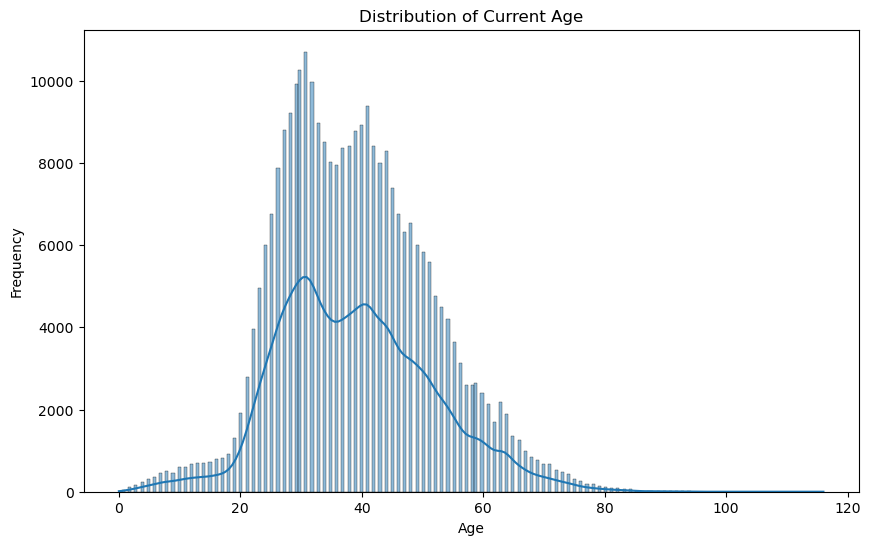

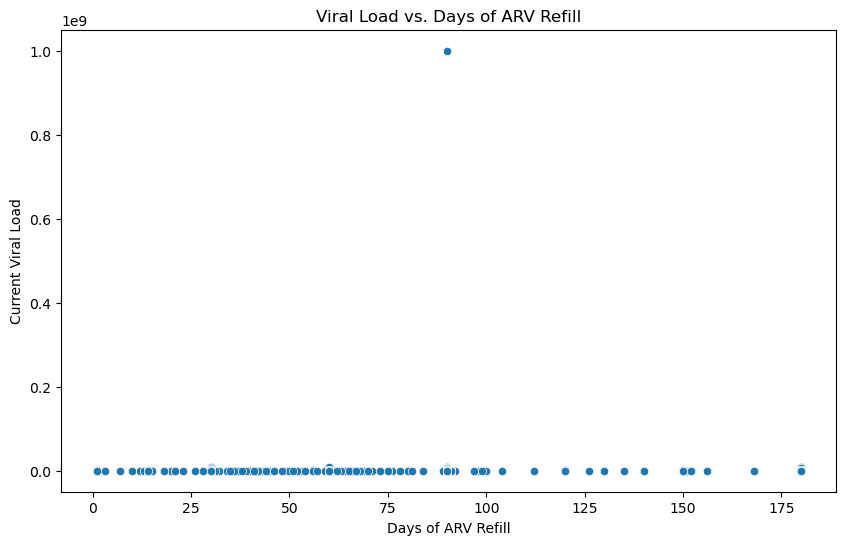

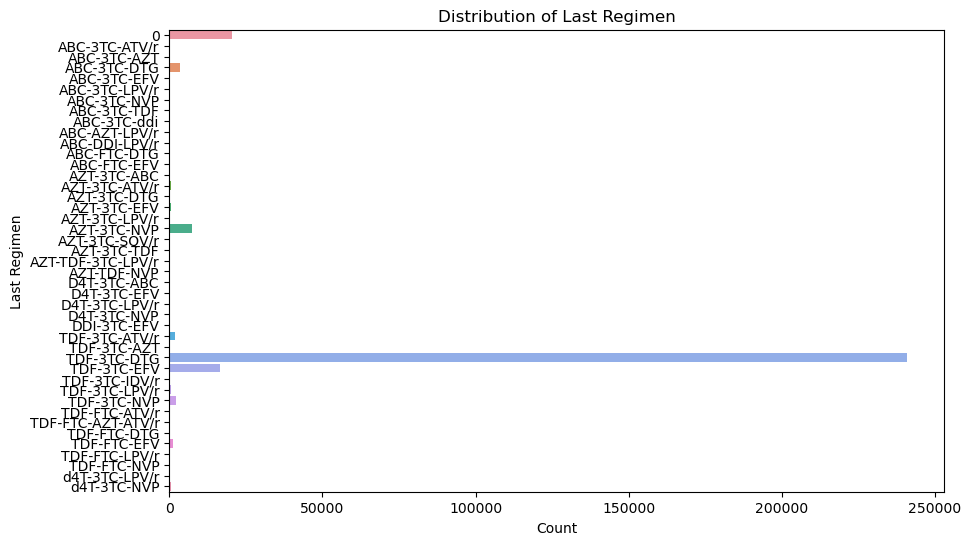

In [94]:
#Visualize the data to see how it looks like before further analysis
# Distribution of current age
plt.figure(figsize=(10, 6))
sns.histplot(hiv_data['Current Age'], kde=True)
plt.title('Distribution of Current Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Viral load vs. Days of ARV Refill
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Days Of ARV Refill', y='Current Viral Load', data=hiv_data)
plt.title('Viral Load vs. Days of ARV Refill')
plt.xlabel('Days of ARV Refill')
plt.ylabel('Current Viral Load')
plt.show()

# Count of different regimens
plt.figure(figsize=(10, 6))
sns.countplot(y='Last Regimen', data=hiv_data)
plt.title('Distribution of Last Regimen')
plt.xlabel('Count')
plt.ylabel('Last Regimen')
plt.show()

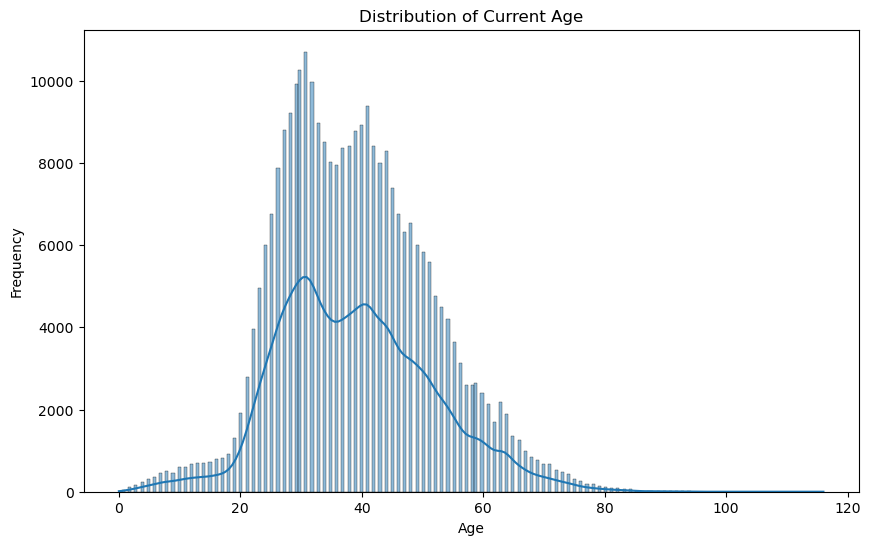

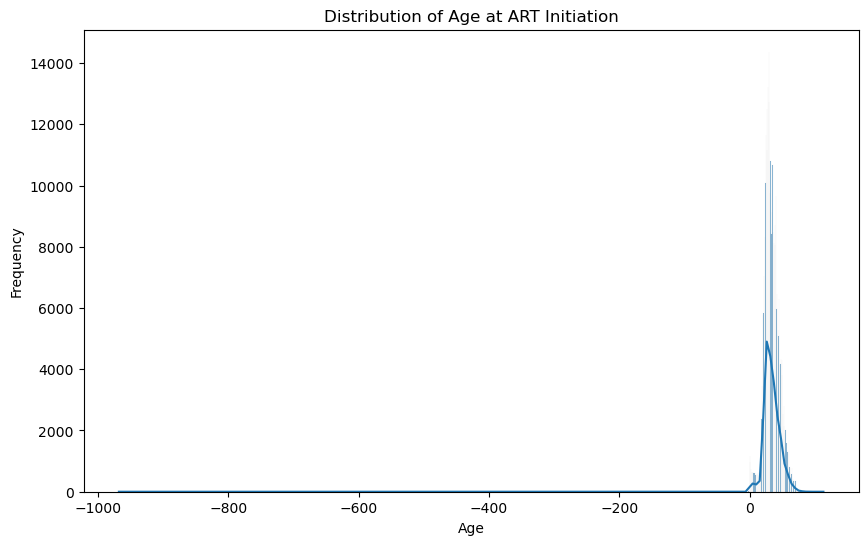

In [95]:
#Analyze the distribution of current age and age at ART initiation.
# Distribution of current age
plt.figure(figsize=(10, 6))
sns.histplot(hiv_data['Current Age'], kde=True)
plt.title('Distribution of Current Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Distribution of age at ART initiation
plt.figure(figsize=(10, 6))
sns.histplot(hiv_data['Age at ART Initiation'], kde=True)
plt.title('Distribution of Age at ART Initiation')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

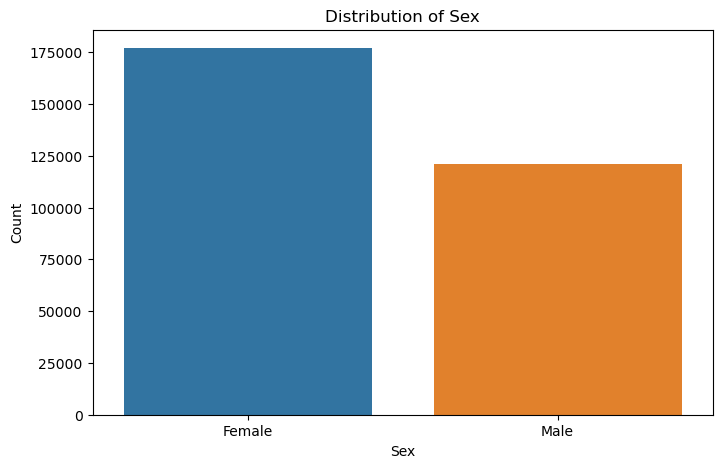

In [96]:
#Analyze the distribution of sex.
# Distribution of sex
plt.figure(figsize=(8, 5))
sns.countplot(data=hiv_data, x='Sex')
plt.title('Distribution of Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

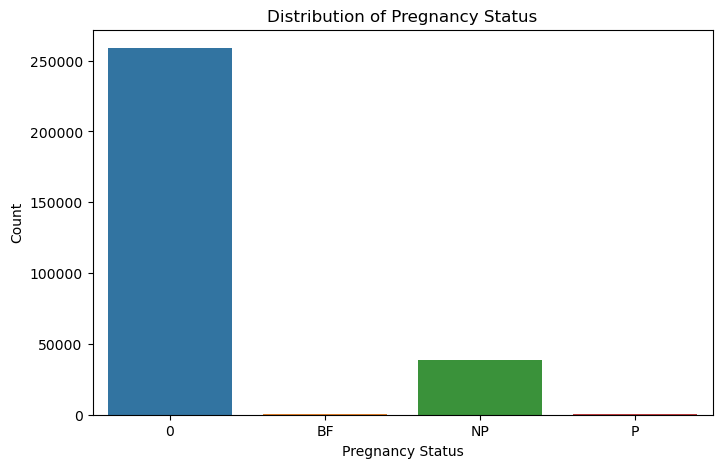

In [97]:
# Analyze the distribution of pregnancy status
plt.figure(figsize=(8, 5))
sns.countplot(data=hiv_data, x='Pregnancy Status')
plt.title('Distribution of Pregnancy Status')
plt.xlabel('Pregnancy Status')
plt.ylabel('Count')
plt.show()

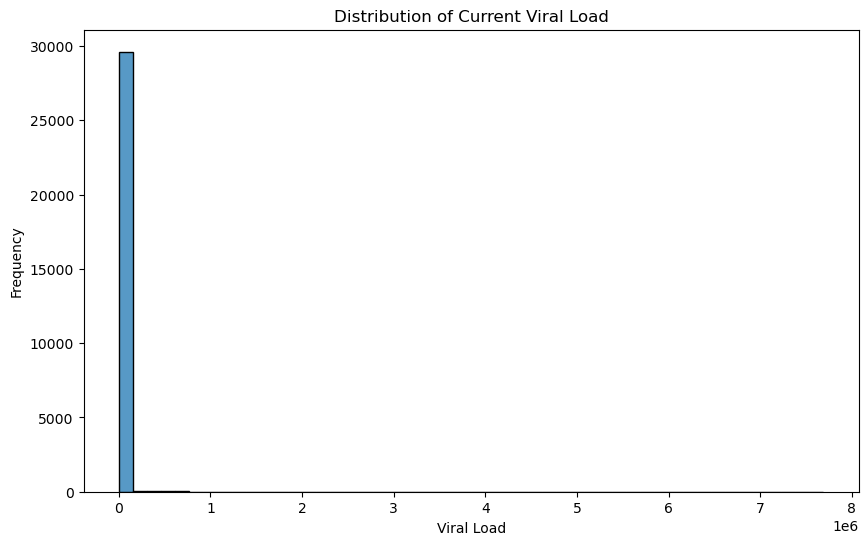

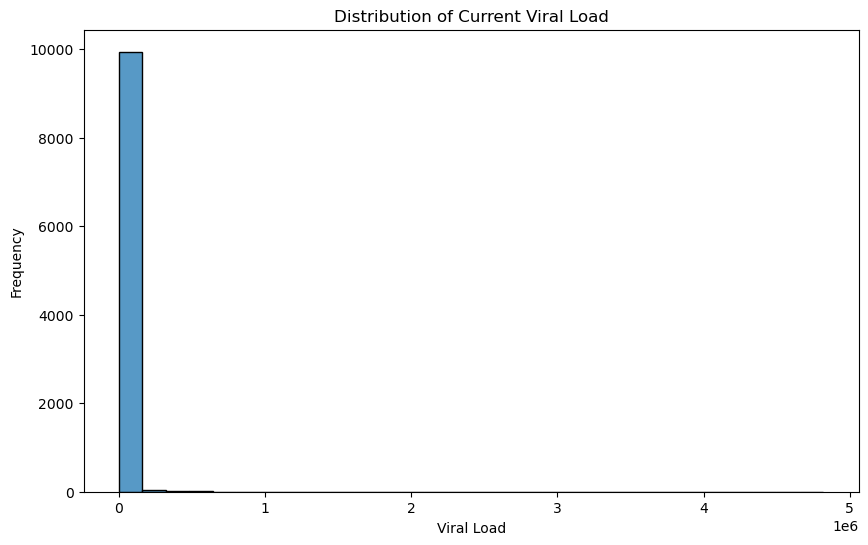

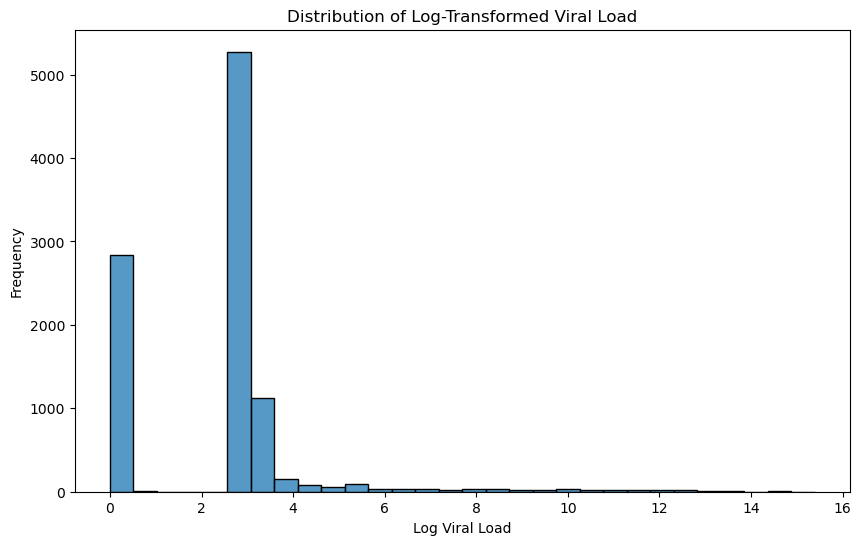

In [98]:
# Select a sample of the data
sampled_data = hiv_data.sample(frac=0.1, random_state=42)  # Use 10% of the data

# Analyze the distribution of current viral load using the sample
plt.figure(figsize=(10, 6))
sns.histplot(sampled_data['Current Viral Load'], bins=50, kde=False)
plt.title('Distribution of Current Viral Load')
plt.xlabel('Viral Load')
plt.ylabel('Frequency')
plt.show()

# optimized the Sampled data for moe visualization
sampled_data = hiv_data.sample(n=10000, random_state=42)  # Use 10,000 rows

# Analyze the distribution of current viral load using the sample
plt.figure(figsize=(10, 6))
sns.histplot(sampled_data['Current Viral Load'], bins=30, kde=False)
plt.title('Distribution of Current Viral Load')
plt.xlabel('Viral Load')
plt.ylabel('Frequency')
plt.show()

# Applied log transformation
hiv_data['Log Viral Load'] = np.log1p(hiv_data['Current Viral Load'])

# Sample the data
sampled_data = hiv_data.sample(n=10000, random_state=42)

# Analyze the distribution of log-transformed viral load using the sample
plt.figure(figsize=(10, 6))
sns.histplot(sampled_data['Log Viral Load'], bins=30, kde=False)
plt.title('Distribution of Log-Transformed Viral Load')
plt.xlabel('Log Viral Load')
plt.ylabel('Frequency')
plt.show()

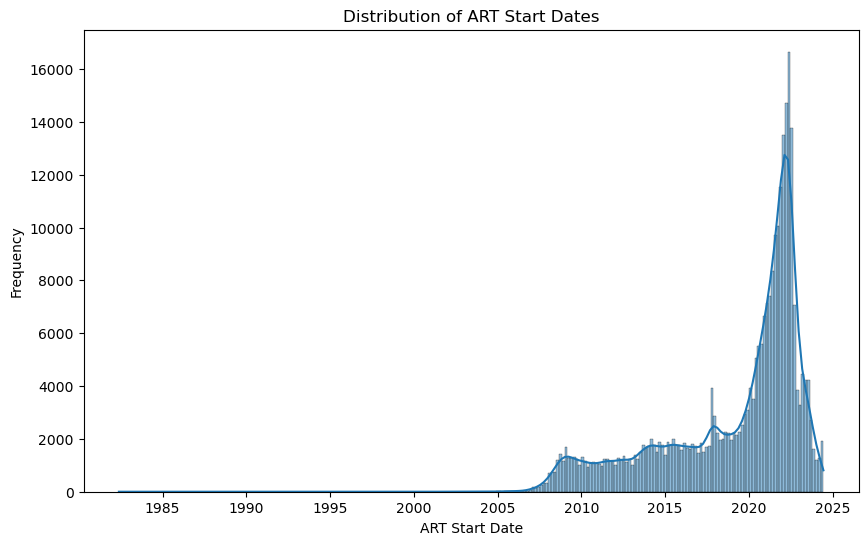

In [99]:
#Analyze the distribution of ART start dates.
# Distribution of ART start dates
plt.figure(figsize=(10, 6))
sns.histplot(hiv_data['ART Start Date'], kde=True)
plt.title('Distribution of ART Start Dates')
plt.xlabel('ART Start Date')
plt.ylabel('Frequency')
plt.show()

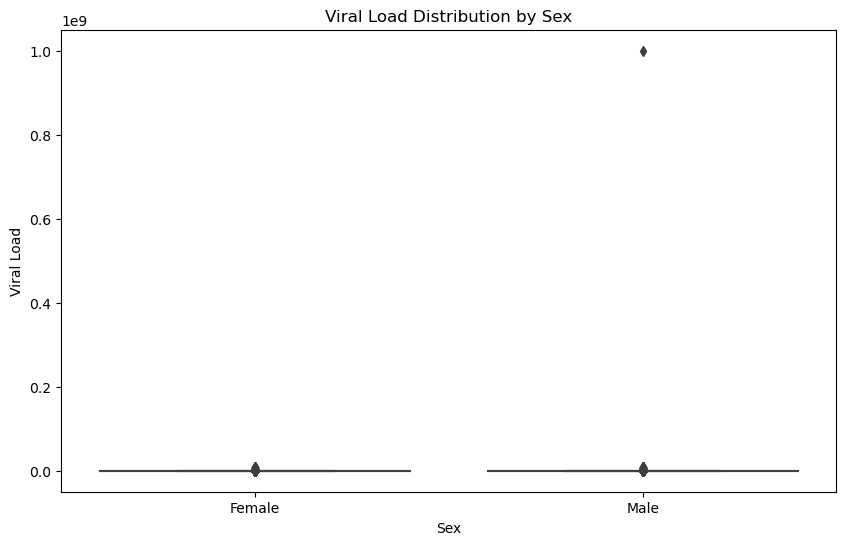

In [100]:
#Analyze the viral load distribution by sex.
# Viral load distribution by sex
plt.figure(figsize=(10, 6))
sns.boxplot(data=hiv_data, x='Sex', y='Current Viral Load')
plt.title('Viral Load Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Viral Load')
plt.show()

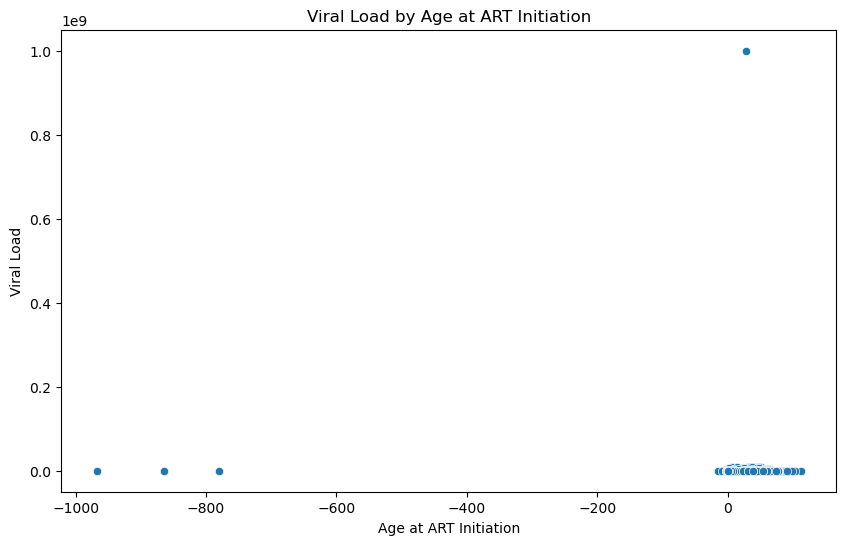

In [101]:
#Analyze the viral load distribution by age at ART initiation.
# Viral load distribution by age at ART initiation
plt.figure(figsize=(10, 6))
sns.scatterplot(data=hiv_data, x='Age at ART Initiation', y='Current Viral Load')
plt.title('Viral Load by Age at ART Initiation')
plt.xlabel('Age at ART Initiation')
plt.ylabel('Viral Load')
plt.show()

In [102]:
#Generate summary statistics for key variables.
# Summary statistics for numerical columns
summary_statistics = hiv_data.describe()
print(summary_statistics)

# Summary statistics for categorical columns
categorical_summary = hiv_data.describe(include=['category'])
print(categorical_summary)

         Patient_Id                  Date Of Birth    Current Age  \
count  2.980820e+05                         298082  298082.000000   
mean   9.937044e+06  1984-12-10 21:03:07.607436736      38.935061   
min    3.012330e+05            1908-02-04 00:00:00       0.000000   
25%    8.559779e+06            1976-11-02 00:00:00      30.000000   
50%    1.122556e+07            1986-01-01 00:00:00      38.000000   
75%    1.162659e+07            1994-03-02 00:00:00      47.000000   
max    1.896213e+07            2024-05-02 00:00:00     116.000000   
std    4.583873e+06                            NaN      12.729094   

       Age at ART Initiation                 ART Start Date  \
count          298082.000000                         298079   
mean               33.716555  2019-02-21 14:31:39.595744512   
min              -968.000000            1982-05-26 00:00:00   
25%                26.000000            2016-09-23 12:00:00   
50%                32.000000            2020-12-30 00:00:00   


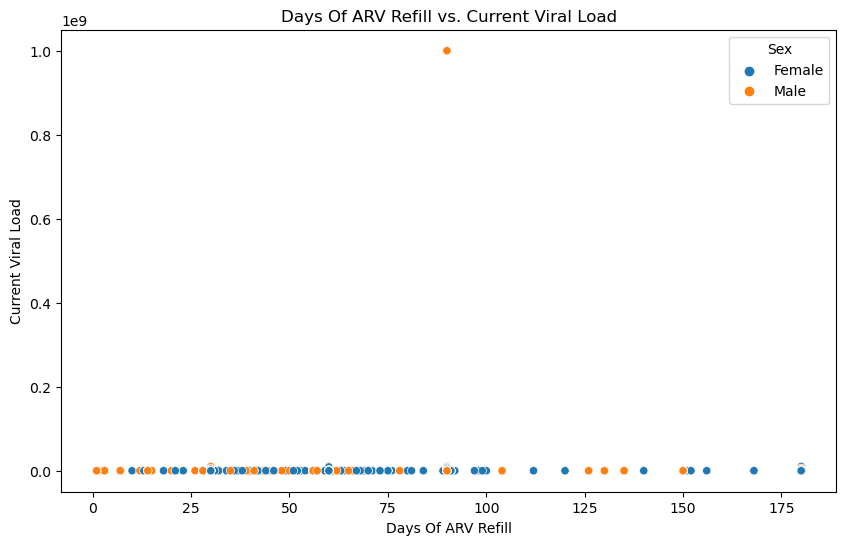

In [103]:
#Explore the relationship between treatment adherence and viral load outcomes.
#Scatter Plot: Days of ARV Refill vs. Viral Load
plt.figure(figsize=(10, 6))
sns.scatterplot(data=hiv_data, x='Days Of ARV Refill', y='Current Viral Load', hue='Sex')
plt.title('Days Of ARV Refill vs. Current Viral Load')
plt.xlabel('Days Of ARV Refill')
plt.ylabel('Current Viral Load')
plt.show()

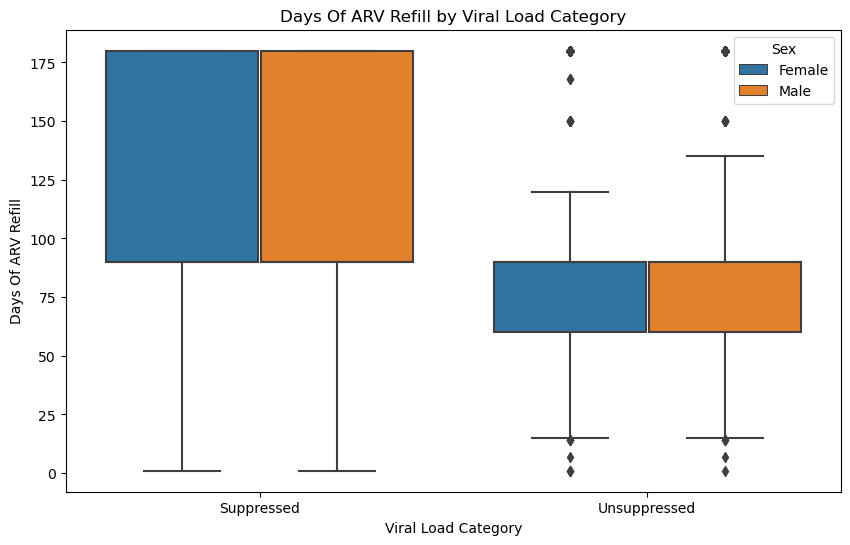

In [104]:
#Box Plot for Days of ARV Refill by Viral Load Category
# Create viral load categories
hiv_data['Viral Load Category'] = hiv_data['Current Viral Load'].apply(lambda x: 'Suppressed' if x < 200 else 'Unsuppressed')

plt.figure(figsize=(10, 6))
sns.boxplot(data=hiv_data, x='Viral Load Category', y='Days Of ARV Refill', hue='Sex')
plt.title('Days Of ARV Refill by Viral Load Category')
plt.xlabel('Viral Load Category')
plt.ylabel('Days Of ARV Refill')
plt.show()

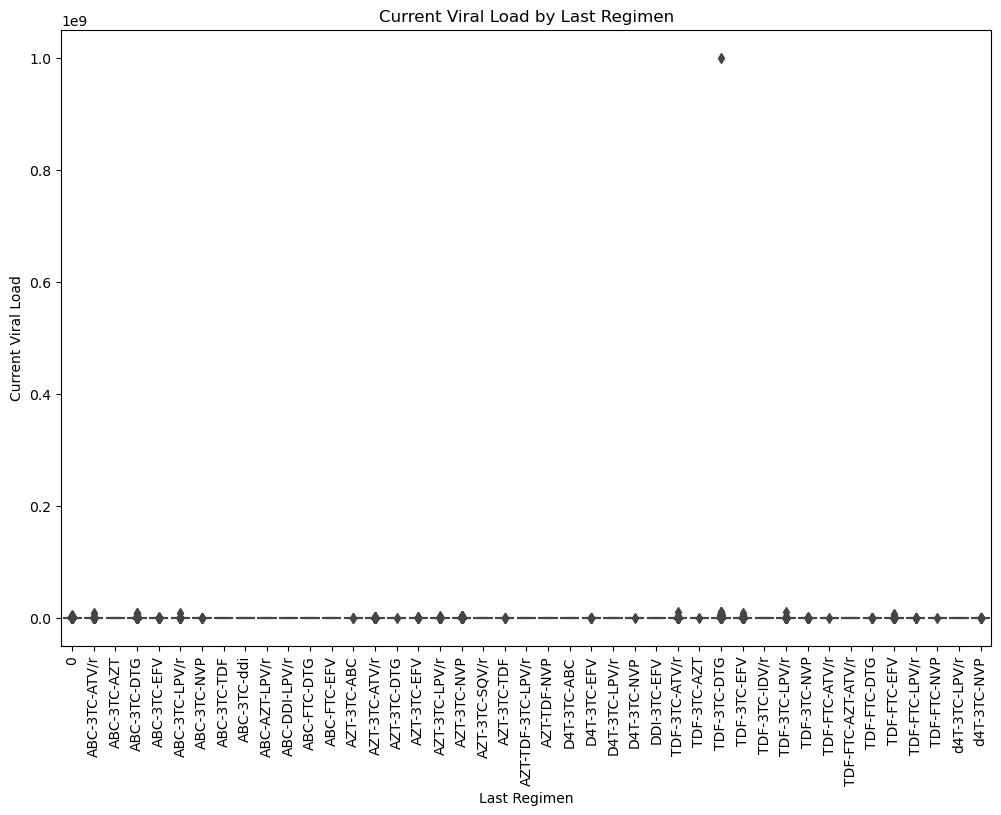

In [105]:
#Analyze the distribution of viral load outcomes across different regimen types.
#Box Plot: Viral Load by Last Regimen
plt.figure(figsize=(12, 8))
sns.boxplot(data=hiv_data, x='Last Regimen', y='Current Viral Load')
plt.title('Current Viral Load by Last Regimen')
plt.xlabel('Last Regimen')
plt.ylabel('Current Viral Load')
plt.xticks(rotation=90)
plt.show()

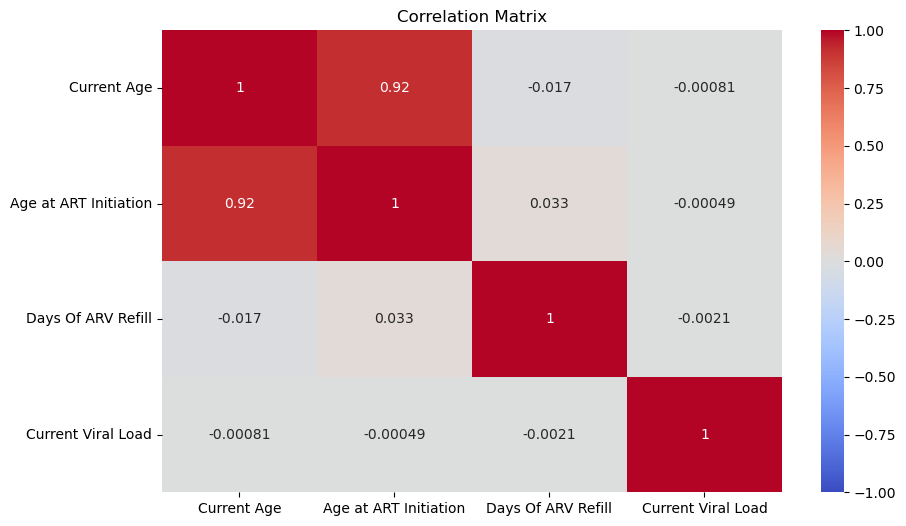

In [106]:
#Compute correlations between numerical features to understand relationships.
# Compute correlation matrix
correlation_matrix = hiv_data[['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 'Current Viral Load']].corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

### //end of adapted code

In [108]:
#Generate summary statistics for key variables by viral load category.
# Summary statistics by viral load category
suppressed_summary = hiv_data[hiv_data['Viral Load Category'] == 'Suppressed'].describe()
unsuppressed_summary = hiv_data[hiv_data['Viral Load Category'] == 'Unsuppressed'].describe()

print("Suppressed Summary:")
print(suppressed_summary)

print("\nUnsuppressed Summary:")
print(unsuppressed_summary)

Suppressed Summary:
         Patient_Id                  Date Of Birth    Current Age  \
count  2.848790e+05                         284879  284879.000000   
mean   1.004388e+07  1985-01-21 02:42:56.142151552      38.823613   
min    3.012330e+05            1908-02-04 00:00:00       0.000000   
25%    8.712342e+06            1977-01-01 00:00:00      30.000000   
50%    1.125726e+07            1986-01-23 00:00:00      38.000000   
75%    1.163921e+07            1994-03-24 00:00:00      47.000000   
max    1.896213e+07            2024-05-02 00:00:00     116.000000   
std    4.516218e+06                            NaN      12.647945   

       Age at ART Initiation                 ART Start Date  \
count          284879.000000                         284876   
mean               33.706865  2019-03-31 06:48:57.058930944   
min              -968.000000            1982-05-26 00:00:00   
25%                26.000000            2016-12-19 00:00:00   
50%                32.000000            202

# Step 5: Model Building, Model Evaluation and Predictive Analysis.### Split the data into training and testing sets to validate the model.
### We choose appropriate models such as; Random Forests, Support Vector Machine (SVM), Naive Bayes, and logistic regression algorithms to predict treatment outcomes based on the available feature
### Evaluate the model using metrics like accuracy, precision, recall, F1-score, and AUC-ROC.###  Fine-tune the model to improve its performance using techniques such as cross-validation and 
### Use the model to identify patients who are at risk of poor treatment outcomes.
### Identify factors that are most predictive of successful or unsuccessful treatment.s.

## Use Random Forest to predict treatment outcome

In [111]:
# Ensure uniform types in categorical columns
categorical_columns = ['Sex', 'Last Regimen']

# Convert all categorical columns to string type
for col in categorical_columns:
    hiv_data[col] = hiv_data[col].astype(str)

# Select features and target
features = ['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 
            'Current Viral Load', 'Sex', 'Last Regimen']
target = 'Viral Load Category'

# Encode categorical variables
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    hiv_data[col] = le.fit_transform(hiv_data[col])
    label_encoders[col] = le

In [112]:
# Split the data into features and target
X = hiv_data[features]
y = hiv_data[target].apply(lambda x: 1 if x == 'Unsuppressed' else 0)  # Binary target variable

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [113]:
# Train the Random Forest classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [114]:
# Predict the treatment outcomes
y_pred = rf_model.predict(X_test)

### // code adapted from Prashant, 2020 and Farzadnekouei, 2023

In [116]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

Accuracy: 1.0
Confusion Matrix:
 [[85512     0]
 [    0  3913]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     85512
           1       1.00      1.00      1.00      3913

    accuracy                           1.00     89425
   macro avg       1.00      1.00      1.00     89425
weighted avg       1.00      1.00      1.00     89425



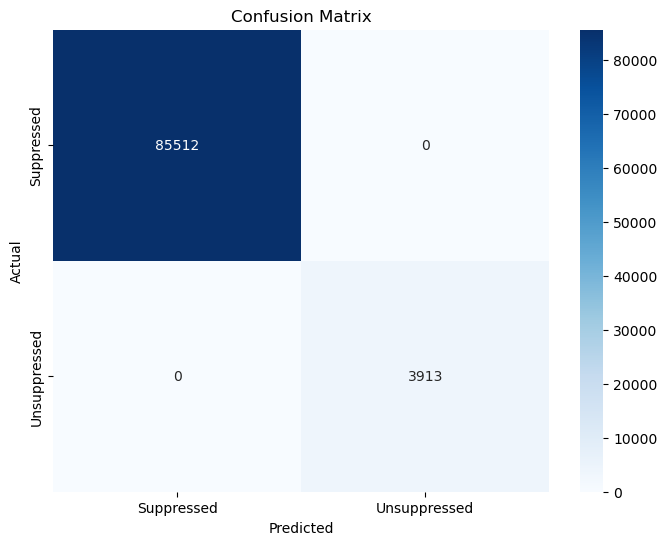

In [117]:
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### We evaluate the Random Forest using metrics like accuracy, precision, recall, F1-score, and AUC-ROC. Fine-tune the model to improve its performance using techniques such as cross-validation and hyperparameter tuning.

In [119]:
# Define the parameter grid for RandomizedSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

# Use RandomizedSearchCV instead of GridSearchCV for quicker search
random_search = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42), param_distributions=param_grid, n_iter=10, cv=5, scoring='roc_auc', n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}


In [120]:
# Train the tuned model
best_params = random_search.best_params_
rf_tuned_model = RandomForestClassifier(random_state=42, **best_params)
rf_tuned_model.fit(X_train, y_train)

# Predict the treatment outcomes with the tuned model
y_tuned_pred = rf_tuned_model.predict(X_test)
y_tuned_prob = rf_tuned_model.predict_proba(X_test)[:, 1]

In [121]:
# Evaluate the tuned model
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)
tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)
tuned_auc_roc = roc_auc_score(y_test, y_tuned_prob)

print("Tuned Model Performance:")
print("Accuracy:", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall:", tuned_recall)
print("F1-Score:", tuned_f1)
print("AUC-ROC:", tuned_auc_roc)

Tuned Model Performance:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0
AUC-ROC: 1.0


In [122]:
# Classification report for tuned model
tuned_class_report = classification_report(y_test, y_tuned_pred)
print("Tuned Classification Report:\n", tuned_class_report)

Tuned Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     85512
           1       1.00      1.00      1.00      3913

    accuracy                           1.00     89425
   macro avg       1.00      1.00      1.00     89425
weighted avg       1.00      1.00      1.00     89425



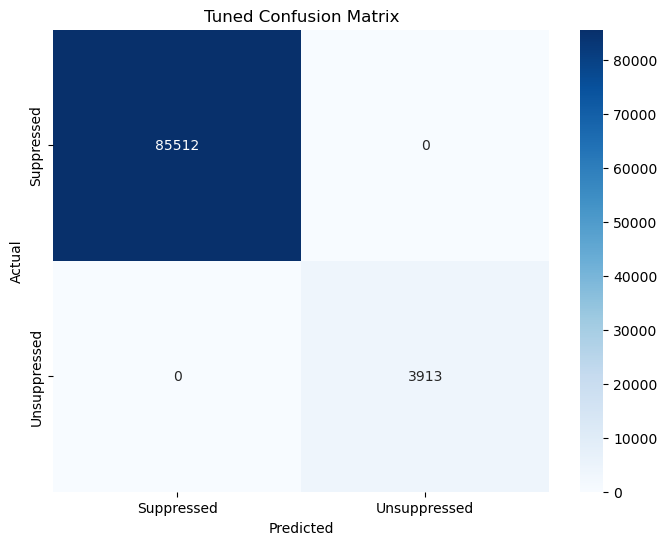

In [123]:
# Confusion matrix for tuned model
tuned_conf_matrix = confusion_matrix(y_test, y_tuned_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(tuned_conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Confusion Matrix')
plt.show()

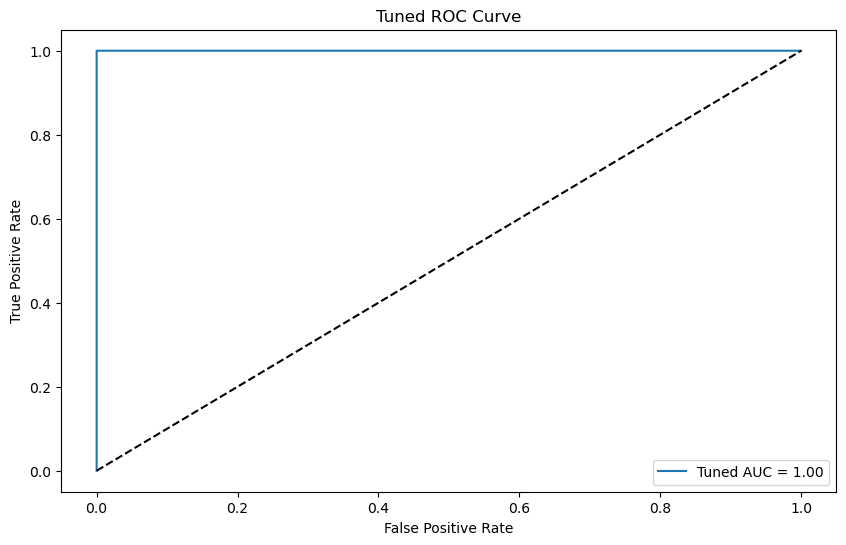

In [124]:
# ROC Curve for tuned model
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_tuned_prob)
plt.figure(figsize=(10, 6))
plt.plot(fpr_tuned, tpr_tuned, label=f'Tuned AUC = {tuned_auc_roc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned ROC Curve')
plt.legend()
plt.show()

### We identify patients who are at risk of poor treatment outcomes and patients with good outcomes.

In [126]:
# Identify high-risk patients (those predicted to have a poor treatment outcome)
# Define the risk threshold (e.g., probability > 0.5)
risk_threshold = 0.5

# Identify patients at risk
high_risk_patients = X_test[y_tuned_prob > risk_threshold]
high_risk_probabilities = y_tuned_prob[y_tuned_prob > risk_threshold]

# Add probabilities to the DataFrame for better interpretation
high_risk_patients = pd.DataFrame(high_risk_patients)
high_risk_patients['risk_probability'] = high_risk_probabilities

print("High-risk patients identified (showing first 10):")
print(high_risk_patients.head(10))

High-risk patients identified (showing first 10):
        Current Age  Age at ART Initiation  Days Of ARV Refill  \
33529            47                     31                90.0   
50635            54                     48                90.0   
30555            31                     25                90.0   
51335            31                     25               180.0   
189715           42                     39               180.0   
59280            65                     52                30.0   
49552            25                     21                90.0   
120571           61                     48                60.0   
153393           35                     32                90.0   
46565            29                     25               180.0   

        Current Viral Load  Sex  Last Regimen  risk_probability  
33529                583.0    0            28          0.991522  
50635                760.0    0            30          0.990515  
30555               2050.

In [127]:
# Identify patients with poor outcomes (assuming '1' indicates a poor outcome)
high_risk_patients = (y_tuned_prob == 1)
high_risk_outcome = X_test[high_risk_patients]

# Create a DataFrame to show these patients
high_risk_patients_info = pd.DataFrame(high_risk_outcome)
high_risk_patients_info['Actual Outcome'] = y_test[high_risk_patients].values
high_risk_patients_info['Predicted Outcome'] = y_tuned_prob[high_risk_patients]

print("Patients with Poor Outcomes:\n", high_risk_patients_info)

Patients with Poor Outcomes:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
13009            52                     40                30.0   
151483           39                     37                90.0   
79004            51                     36                30.0   
29765            55                     40                60.0   
117496           41                     37                90.0   
...             ...                    ...                 ...   
237840           41                     37                90.0   
144667           40                     38                90.0   
9794             37                     32                90.0   
169343           40                     38                90.0   
91527            51                     36                60.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
13009                200.0    1             0               1   
151483               953.0    0            30  

In [128]:
# Identify patients with good outcomes (assuming '0' indicates a good outcome)
good_outcome_indices = (y_tuned_prob == 0)
good_outcome_patients = X_test[good_outcome_indices]

# Create a DataFrame to show these patients
good_outcome_patients_info = pd.DataFrame(good_outcome_patients)
good_outcome_patients_info['Actual Outcome'] = y_test[good_outcome_indices].values
good_outcome_patients_info['Predicted Outcome'] = y_tuned_prob[good_outcome_indices]

print("Patients with Good Outcomes:\n", good_outcome_patients_info)

Patients with Good Outcomes:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
296549           47                     32                90.0   
237447           43                     35                90.0   
255214           40                     38                90.0   
121365           41                     39                90.0   
255894           41                     38                90.0   
...             ...                    ...                 ...   
95098            37                     33                90.0   
112469           41                     39                90.0   
220069           37                     33                90.0   
118595           39                     37                90.0   
5640             40                     38                90.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
296549                 0.0    0             0               0   
237447                 0.0    0             0  

### We identify factors that are most predictive of successful or unsuccessful treatment.

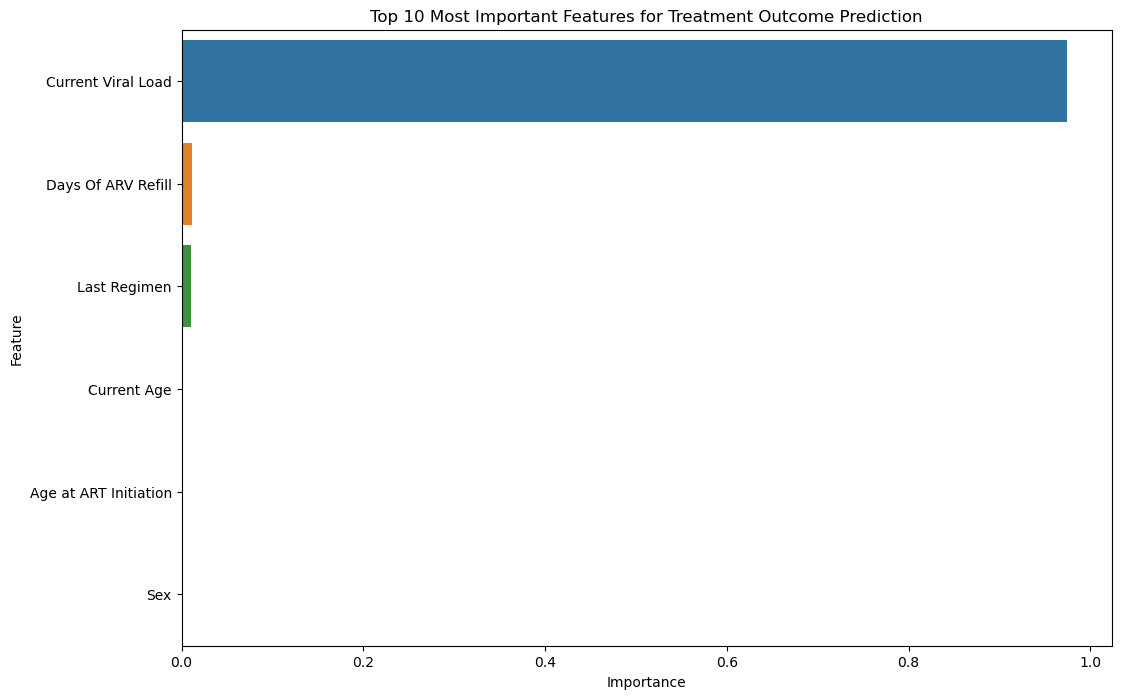

Top 10 Most Important Features:
                  Feature  Importance
3     Current Viral Load    0.974464
2     Days Of ARV Refill    0.011739
5           Last Regimen    0.010341
0            Current Age    0.001754
1  Age at ART Initiation    0.001630
4                    Sex    0.000072


In [130]:
# Extract feature importances
feature_importances = rf_tuned_model.feature_importances_

# Create a DataFrame for better interpretation
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
})

# Sort the DataFrame by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Visualize the top 10 features
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10))
plt.title('Top 10 Most Important Features for Treatment Outcome Prediction')
plt.show()

# Print the top 10 features
print("Top 10 Most Important Features:\n", feature_importance_df.head(10))

# WE will use Support Vector Machine(SVM) to predict treatment outcome

In [132]:
# Ensure uniform types in categorical columns
categorical_columns = ['Sex', 'Last Regimen']

# Convert all categorical columns to string type
for col in categorical_columns:
    hiv_data[col] = hiv_data[col].astype(str)

# Select features and target
features = ['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 
            'Current Viral Load', 'Sex', 'Last Regimen']
target = 'Viral Load Category'

# Encode categorical variables
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    hiv_data[col] = le.fit_transform(hiv_data[col])
    label_encoders[col] = le

In [133]:
# Split the data into features and target
X = hiv_data[features]
y = hiv_data[target].apply(lambda x: 1 if x == 'Unsuppressed' else 0)  # Binary target variable

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [134]:
svm = SVC(kernel='linear', probability=True)
svm.fit(X_train, y_train)

SVC(kernel='linear', probability=True)

In [135]:
# Step 2: Train the Linear SVM Model
svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

SVC(kernel='linear', probability=True, random_state=42)

In [136]:
# Make predictions
y_svm_pred = svm.predict(X_test)

In [137]:
# Evaluate the SVM model
svm_accuracy = accuracy_score(y_test, y_svm_pred)
svm_precision = precision_score(y_test, y_svm_pred)
svm_recall = recall_score(y_test, y_svm_pred)
svm_f1 = f1_score(y_test, y_svm_pred)

print("SVM Model Performance:")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1-Score:", svm_f1)

SVM Model Performance:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


In [138]:
# Classification report for SVM model
svm_class_report = classification_report(y_test, y_svm_pred)
print("SVM Classification Report:\n", svm_class_report)

SVM Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     85512
           1       1.00      1.00      1.00      3913

    accuracy                           1.00     89425
   macro avg       1.00      1.00      1.00     89425
weighted avg       1.00      1.00      1.00     89425



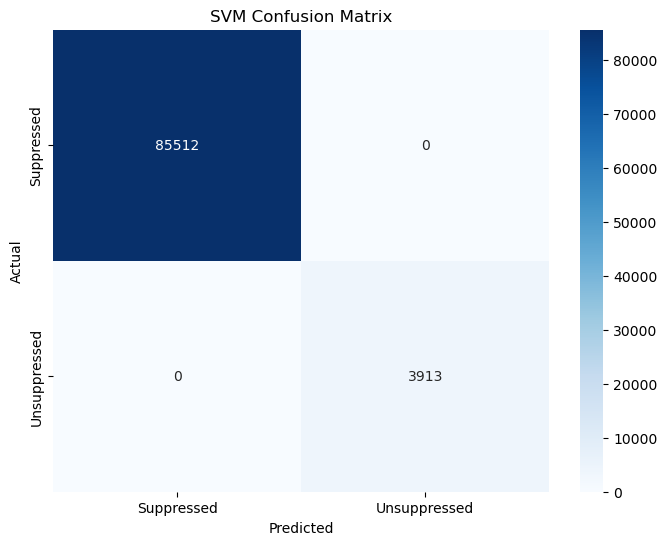

In [139]:
# Confusion matrix for SVM model
svm_conf_matrix = confusion_matrix(y_test, y_svm_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(svm_conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

### We evaluate the Support Vector Machine(SVM) using metrics like accuracy, precision, recall, F1-score, and AUC-ROC. Fine-tune the model to improve its performance using techniques such as cross-validation and hyperparameter tuning.¶

In [141]:
# Define a minimal parameter grid for initial testing
param_grid = {
    'C': [1, 10],
    'gamma': [0.1, 0.01],
    'kernel': ['linear', 'rbf']
}

# Set up GridSearchCV with cross-validation
grid_search = GridSearchCV(SVC(probability=True), param_grid, refit=True, verbose=2, cv=3, scoring='accuracy')

print("Grid search setup completed.")

Grid search setup completed.


In [142]:
# Use a smaller subset for initial testing
X_train_subset = X_train[:100]
y_train_subset = y_train[:100]

print("Subset of data created for initial testing.")

Subset of data created for initial testing.


In [143]:
# Train the model with grid search on the subset
grid_search.fit(X_train_subset, y_train_subset)

# Get the best parameters
print("Best parameters found: ", grid_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END ......................C=1, gamma=0.1, kernel=linear; total time=   0.0s
[CV] END ......................C=1, gamma=0.1, kernel=linear; total time=   0.0s
[CV] END ......................C=1, gamma=0.1, kernel=linear; total time=   0.0s
[CV] END .........................C=1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .........................C=1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .........................C=1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .....................C=1, gamma=0.01, kernel=linear; total time=   0.0s
[CV] END .....................C=1, gamma=0.01, kernel=linear; total time=   0.0s
[CV] END .....................C=1, gamma=0.01, kernel=linear; total time=   0.0s
[CV] END ........................C=1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ........................C=1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ........................C=1, gamma=0.01,

In [144]:
# Get the best model
best_svm_model = grid_search.best_estimator_

print("Best model obtained.")

Best model obtained.


In [145]:
# Make predictions
y_pred = best_svm_model.predict(X_test)
y_prob = best_svm_model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_prob)

print("SVM Model Performance:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("AUC-ROC:", auc_roc)

SVM Model Performance:
Accuracy: 0.9782051998881744
Precision: 1.0
Recall: 0.5019166879631995
F1-Score: 0.6683682150757189
AUC-ROC: 1.0


In [146]:
# Classification report
class_report = classification_report(y_test, y_pred)
print("SVM Classification Report:\n", class_report)

SVM Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99     85512
           1       1.00      0.50      0.67      3913

    accuracy                           0.98     89425
   macro avg       0.99      0.75      0.83     89425
weighted avg       0.98      0.98      0.97     89425



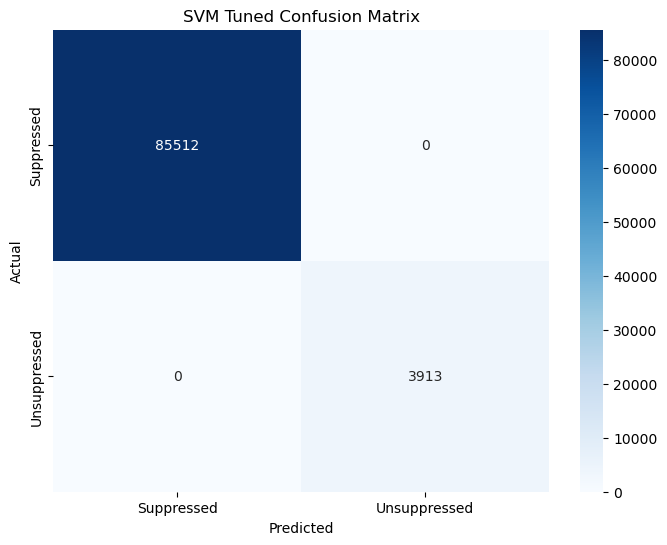

In [147]:
# Confusion matrix
tuned_conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Tuned Confusion Matrix')
plt.show()

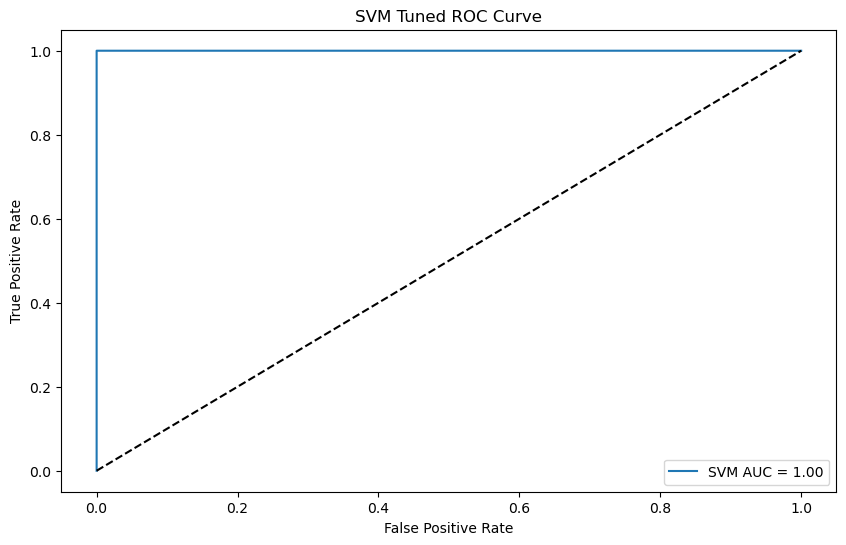

In [148]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'SVM AUC = {auc_roc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SVM Tuned ROC Curve')
plt.legend()
plt.show()

### We identify patients who are at risk of poor treatment outcomes and patients with good outcomes.


In [150]:
# Assuming '1' indicates poor outcome (Unsuppressed)

# Identify high-risk patients
high_risk_indices = (y_pred == 1)  # Patients predicted to have poor outcomes
high_risk_patients = X_test[high_risk_indices]

# Create a DataFrame to show these patients
high_risk_patients_info = pd.DataFrame(high_risk_patients)
high_risk_patients_info['Actual Outcome'] = y_test[high_risk_indices]
high_risk_patients_info['Predicted Outcome'] = y_pred[high_risk_indices]

print("High-Risk Patients:\n", high_risk_patients_info)

High-Risk Patients:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
189715           42                     39               180.0   
59280            65                     52                30.0   
49552            25                     21                90.0   
153393           35                     32                90.0   
46565            29                     25               180.0   
...             ...                    ...                 ...   
146405           38                     25                90.0   
285451           44                     43               180.0   
231523           29                     23               180.0   
35167            38                     31                90.0   
186034            7                      3                90.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
189715              7224.0    0            24               1   
59280              63524.0    0             0           

In [151]:
# Identify high-risk patients (those predicted to have a poor treatment outcome)
# Define the risk threshold (e.g., probability > 0.5)
risk_threshold = 0.5

# Identify patients at risk
high_risk_patients = X_test[y_tuned_prob > risk_threshold]
high_risk_probabilities = y_tuned_prob[y_tuned_prob > risk_threshold]

# Add probabilities to the DataFrame for better interpretation
high_risk_patients = pd.DataFrame(high_risk_patients)
high_risk_patients['risk_probability'] = high_risk_probabilities

print("High-risk patients identified (showing first 10):")
print(high_risk_patients.head(10))

High-risk patients identified (showing first 10):
        Current Age  Age at ART Initiation  Days Of ARV Refill  \
33529            47                     31                90.0   
50635            54                     48                90.0   
30555            31                     25                90.0   
51335            31                     25               180.0   
189715           42                     39               180.0   
59280            65                     52                30.0   
49552            25                     21                90.0   
120571           61                     48                60.0   
153393           35                     32                90.0   
46565            29                     25               180.0   

        Current Viral Load  Sex  Last Regimen  risk_probability  
33529                583.0    0            21          0.991522  
50635                760.0    0            24          0.990515  
30555               2050.

In [152]:
# Assuming '0' indicates good outcome (Suppressed)

# Identify patients with good outcomes
good_outcome_indices = (y_pred == 0)  # Patients predicted to have good outcomes
good_outcome_patients = X_test[good_outcome_indices]

# Create a DataFrame to show these patients
good_outcome_patients_info = pd.DataFrame(good_outcome_patients)
good_outcome_patients_info['Actual Outcome'] = y_test[good_outcome_indices]
good_outcome_patients_info['Predicted Outcome'] = y_pred[good_outcome_indices]

print("Patients with Good Outcomes:\n", good_outcome_patients_info)

Patients with Good Outcomes:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
263487           24                     20                90.0   
33529            47                     31                90.0   
225590           31                     27                90.0   
129805           28                     26               180.0   
259492            4                      2                90.0   
...             ...                    ...                 ...   
245305           25                     23                90.0   
63990            38                     22               180.0   
161583           26                     24                90.0   
119605           40                     32                90.0   
219185           23                     19               180.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
263487                19.0    0            24               0   
33529                583.0    0            21  

### We identify factors that are most predictive of successful or unsuccessful treatment.


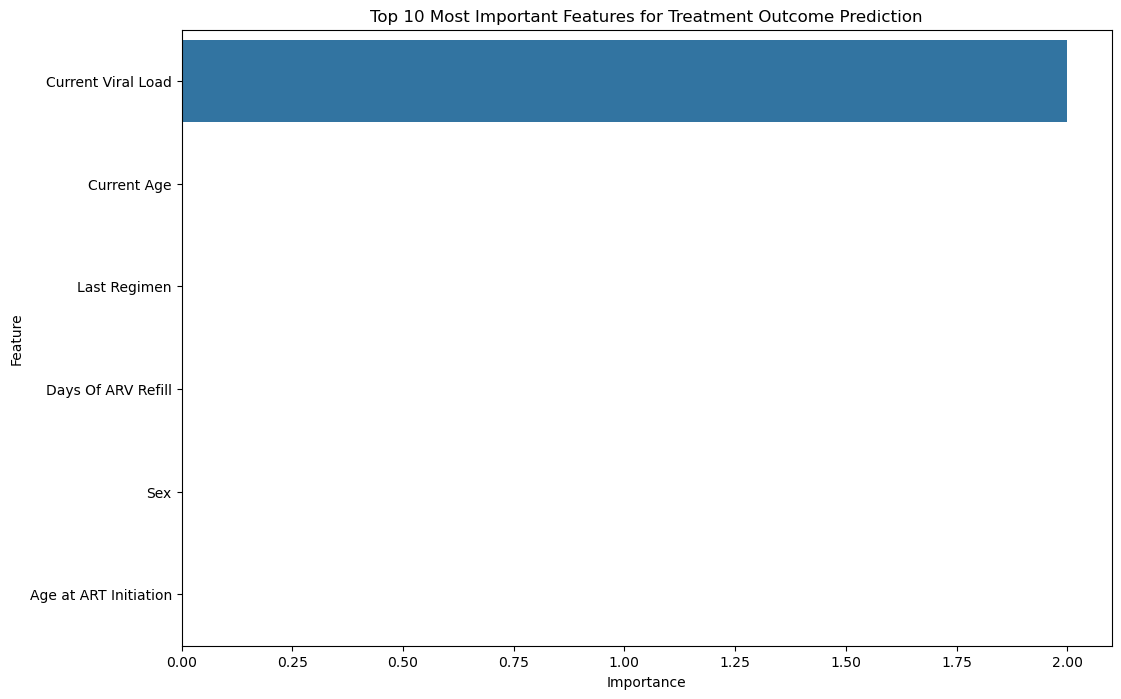

Top 10 Most Important Features:
                  Feature    Importance
3     Current Viral Load  1.999777e+00
0            Current Age  1.890145e-06
5           Last Regimen  5.577403e-07
2     Days Of ARV Refill  1.516708e-07
4                    Sex  6.572520e-14
1  Age at ART Initiation -1.395448e-06


In [154]:
# Step 4: Identify Important Features
feature_columns = X_train.columns  # Ensure this corresponds to your feature column names

# Get the coefficients from the linear SVM model
coef = svm_model.coef_[0]

# Create a DataFrame for feature importance
feature_importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': coef
})

# Sort the DataFrame by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Visualize the top 10 features
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10))
plt.title('Top 10 Most Important Features for Treatment Outcome Prediction')
plt.show()

# Print the top 10 features
print("Top 10 Most Important Features:\n", feature_importance_df.head(10))

## We will use Naive Bayes to predict treatment outcome

In [156]:
# Ensure uniform types in categorical columns
categorical_columns = ['Sex', 'Last Regimen']

# Convert all categorical columns to string type
for col in categorical_columns:
    hiv_data[col] = hiv_data[col].astype(str)

# Select features and target
features = ['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 
            'Current Viral Load', 'Sex', 'Last Regimen']
target = 'Viral Load Category'

# Encode categorical variables
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    hiv_data[col] = le.fit_transform(hiv_data[col])
    label_encoders[col] = le

In [157]:
# Split the data into features and target
X = hiv_data[features]
y = hiv_data[target].apply(lambda x: 1 if x == 'Unsuppressed' else 0)  # Binary target variable

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [158]:
# Train the Naive Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

In [159]:
# Predict the treatment outcomes
y_pred = nb_model.predict(X_test)

In [160]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

Accuracy: 0.9910986860497624
Confusion Matrix:
 [[85512     0]
 [  796  3117]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00     85512
           1       1.00      0.80      0.89      3913

    accuracy                           0.99     89425
   macro avg       1.00      0.90      0.94     89425
weighted avg       0.99      0.99      0.99     89425



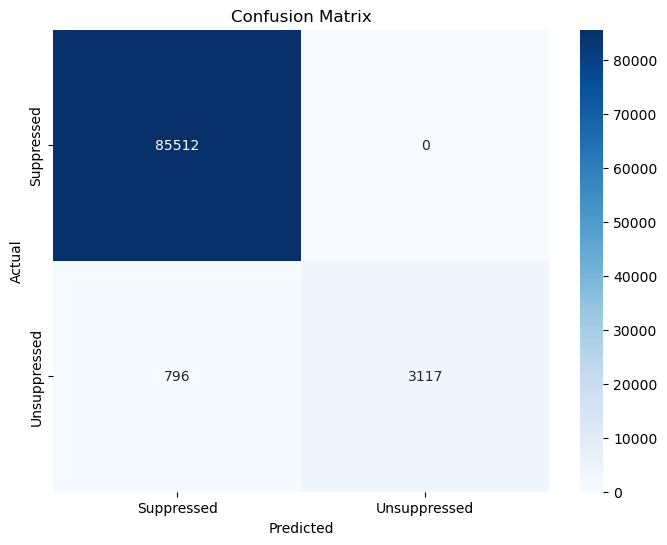

In [161]:
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### We evaluate the Naive Bayes using metrics like accuracy, precision, recall, F1-score, and AUC-ROC. Fine-tune the model to improve its performance using techniques such as cross-validation and hyperparameter tuning.¶


In [163]:
# Define the parameter grid (for GaussianNB there are not many parameters, but we can tune `var_smoothing`)
param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

# Set up the GridSearchCV with cross-validation
grid_search = GridSearchCV(GaussianNB(), param_grid, refit=True, verbose=2, cv=5, scoring='accuracy')

# Train the model with grid search
grid_search.fit(X_train, y_train)

# Get the best parameters
print("Best parameters found: ", grid_search.best_params_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ................................var_smoothing=1e-09; total time=   0.0s
[CV] END ................................var_smoothing=1e-09; total time=   0.0s
[CV] END ................................var_smoothing=1e-09; total time=   0.0s
[CV] END ................................var_smoothing=1e-09; total time=   0.0s
[CV] END ................................var_smoothing=1e-09; total time=   0.0s
[CV] END ................................var_smoothing=1e-08; total time=   0.0s
[CV] END ................................var_smoothing=1e-08; total time=   0.0s
[CV] END ................................var_smoothing=1e-08; total time=   0.0s
[CV] END ................................var_smoothing=1e-08; total time=   0.0s
[CV] END ................................var_smoothing=1e-08; total time=   0.0s
[CV] END ................................var_smoothing=1e-07; total time=   0.0s
[CV] END ................................var_smoo

In [164]:
# Evaluate the best model from grid search
best_nb_model = grid_search.best_estimator_
y_pred_best = best_nb_model.predict(X_test)
y_prob_best = best_nb_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics for the best model
accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
auc_roc_best = roc_auc_score(y_test, y_prob_best)

print("Tuned Naive Bayes Model Performance:")
print("Accuracy:", accuracy_best)
print("Precision:", precision_best)
print("Recall:", recall_best)
print("F1-Score:", f1_best)
print("AUC-ROC:", auc_roc_best)

Tuned Naive Bayes Model Performance:
Accuracy: 0.9910986860497624
Precision: 1.0
Recall: 0.7965755175057501
F1-Score: 0.8867709815078236
AUC-ROC: 0.9999998804572949


In [165]:
# Classification report
class_report = classification_report(y_test, y_pred)
print("Naive Bayes Classification Report:\n", class_report)

Naive Bayes Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00     85512
           1       1.00      0.80      0.89      3913

    accuracy                           0.99     89425
   macro avg       1.00      0.90      0.94     89425
weighted avg       0.99      0.99      0.99     89425



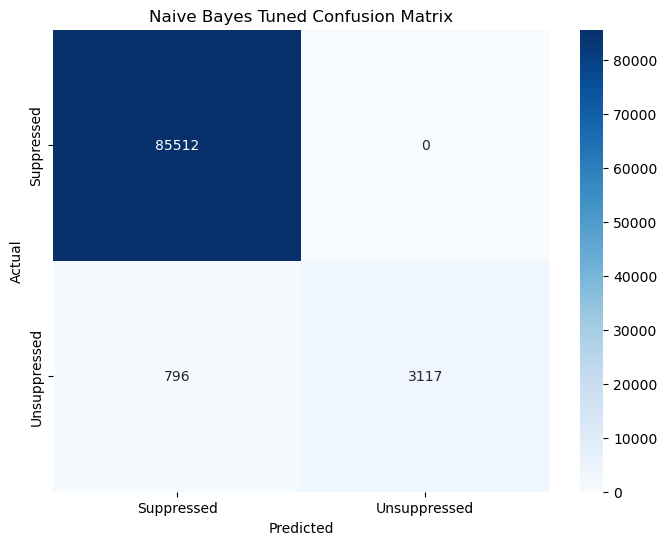

In [166]:
# Confusion matrix
tuned_conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Tuned Confusion Matrix')
plt.show()

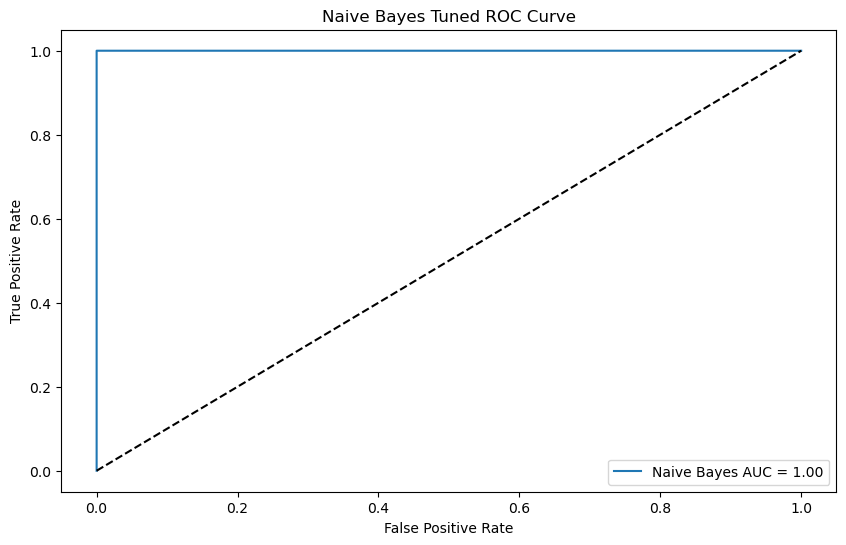

In [167]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'Naive Bayes AUC = {auc_roc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Naive Bayes Tuned ROC Curve')
plt.legend()
plt.show()

### We identify patients who are at risk of poor treatment outcomes and patients with good outcomes.


In [169]:
# Assuming '1' indicates a poor outcome (Unsuppressed), and '0' indicates a good outcome (Suppressed)

# Identify patients with poor predicted outcomes
poor_outcome_indices = (y_pred == 1)
poor_outcome_patients = X_test[poor_outcome_indices]

# Create a DataFrame to show these patients
poor_outcome_patients_info = poor_outcome_patients.copy()
poor_outcome_patients_info['Actual Outcome'] = y_test[poor_outcome_indices]
poor_outcome_patients_info['Predicted Outcome'] = y_pred[poor_outcome_indices]

print("Patients at Risk of Poor Outcomes:\n", poor_outcome_patients_info)

Patients at Risk of Poor Outcomes:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
33529            47                     31                90.0   
50635            54                     48                90.0   
30555            31                     25                90.0   
189715           42                     39               180.0   
59280            65                     52                30.0   
...             ...                    ...                 ...   
231523           29                     23               180.0   
66727            38                     22                30.0   
35167            38                     31                90.0   
39717            52                     37                30.0   
186034            7                      3                90.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
33529                583.0    0            14               1   
50635                760.0    0          

In [170]:
# Assuming '0' indicates a good outcome (Suppressed), and '1' indicates a poor outcome (Unsuppressed)

# Identify patients with good predicted outcomes
good_outcome_indices = (y_pred == 0)
good_outcome_patients = X_test[good_outcome_indices]

# Create a DataFrame to show these patients
good_outcome_patients_info = good_outcome_patients.copy()
good_outcome_patients_info['Actual Outcome'] = y_test[good_outcome_indices]
good_outcome_patients_info['Predicted Outcome'] = y_pred[good_outcome_indices]

print("Patients with Good Outcomes:\n", good_outcome_patients_info)

Patients with Good Outcomes:
         Current Age  Age at ART Initiation  Days Of ARV Refill  \
263487           24                     20                90.0   
225590           31                     27                90.0   
129805           28                     26               180.0   
259492            4                      2                90.0   
38426            41                     35               180.0   
...             ...                    ...                 ...   
245305           25                     23                90.0   
63990            38                     22               180.0   
161583           26                     24                90.0   
119605           40                     32                90.0   
219185           23                     19               180.0   

        Current Viral Load  Sex  Last Regimen  Actual Outcome  \
263487                19.0    0            17               0   
225590                 0.0    1            17  

### We identify factors that are most predictive of successful or unsuccessful treatment.


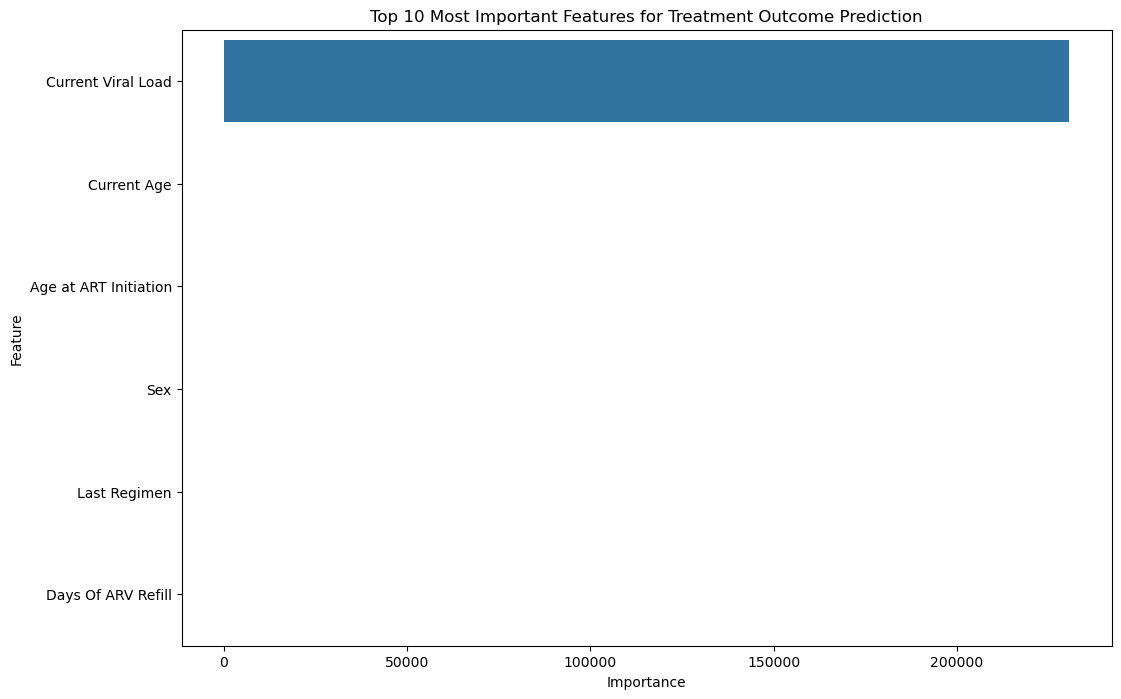

Top 10 Most Important Features:
                  Feature     Importance
3     Current Viral Load  230677.285808
0            Current Age       2.506324
1  Age at ART Initiation       0.211620
4                    Sex      -0.011272
5           Last Regimen      -2.288376
2     Days Of ARV Refill     -13.707505


In [172]:
# Get the log probabilities
log_prob_class_0 = nb_model.theta_[0]
log_prob_class_1 = nb_model.theta_[1]

# Calculate the difference in log probabilities between the two classes
feature_importance = log_prob_class_1 - log_prob_class_0

# Create a DataFrame to hold feature names and their importance
feature_names = X.columns  # Ensure X is the DataFrame with feature names
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Sort the DataFrame by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Visualize the top 10 features
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10))
plt.title('Top 10 Most Important Features for Treatment Outcome Prediction')
plt.show()

# Print the top 10 features
print("Top 10 Most Important Features:\n", feature_importance_df.head(10))


# We will use Logistic Regression to predict treatment outcome

In [174]:
# Ensure uniform types in categorical columns
categorical_columns = ['Sex', 'Last Regimen']

# Convert all categorical columns to string type
for col in categorical_columns:
    hiv_data[col] = hiv_data[col].astype(str)

# Select features and target
features = ['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 
            'Current Viral Load', 'Sex', 'Last Regimen']
target = 'Viral Load Category'

# Encode categorical variables
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    hiv_data[col] = le.fit_transform(hiv_data[col])
    label_encoders[col] = le

In [175]:
# Split the data into features and target
X = hiv_data[features]
y = hiv_data[target].apply(lambda x: 1 if x == 'Unsuppressed' else 0)  # Binary target variable

# Standardize the numerical features
scaler = StandardScaler()
X[['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 'Current Viral Load']] = scaler.fit_transform(
    X[['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 'Current Viral Load']]
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

C:\Users\HP\AppData\Local\Temp\ipykernel_14528\551245669.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['Current Age', 'Age at ART Initiation', 'Days Of ARV Refill', 'Current Viral Load']] = scaler.fit_transform(


In [176]:
# Train the logistic regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [177]:
# Predict the treatment outcomes
y_pred = lr_model.predict(X_test)

In [178]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

Accuracy: 0.9645401174168298
Confusion Matrix:
 [[85511     1]
 [ 3170   743]]
Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98     85512
           1       1.00      0.19      0.32      3913

    accuracy                           0.96     89425
   macro avg       0.98      0.59      0.65     89425
weighted avg       0.97      0.96      0.95     89425



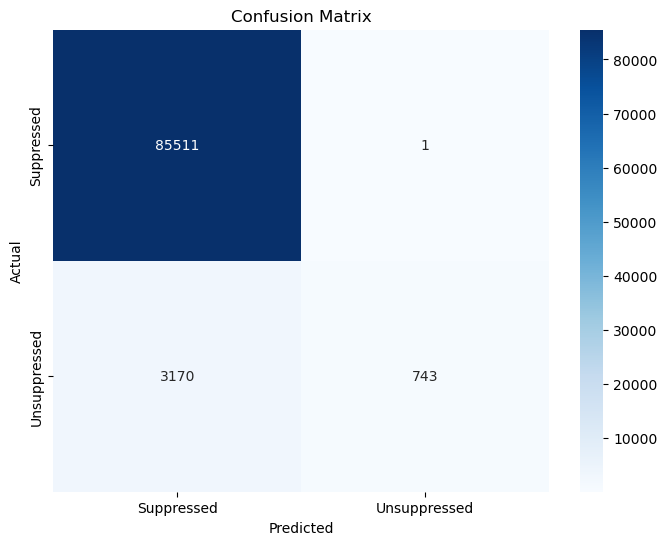

In [179]:
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Suppressed', 'Unsuppressed'], yticklabels=['Suppressed', 'Unsuppressed'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### We evaluate the Logistic Regression using metrics like accuracy, precision, recall, F1-score, and AUC-ROC. Fine-tune the model to improve its performance using techniques such as cross-validation and hyperparameter tuning.

In [181]:
# Load and preprocess data
# Example:
# X = df.drop(columns=[target_variable_name])
# y = df[target_variable_name]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standard scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Smaller subset for initial hyperparameter tuning
X_train_small, _, y_train_small, _ = train_test_split(X_train, y_train, test_size=0.8, random_state=42)

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'C': [0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['saga']
}

# Set up the GridSearchCV with cross-validation
grid_search = GridSearchCV(LogisticRegression(max_iter=10000), param_grid, refit=True, verbose=1, cv=5, scoring='accuracy')
grid_search.fit(X_train_small, y_train_small)

# Get the best parameters
print("Best parameters found: ", grid_search.best_params_)

# Use the best parameters to train on the full dataset
best_params = grid_search.best_params_
best_lr_model = LogisticRegression(**best_params, max_iter=10000)
best_lr_model.fit(X_train, y_train)

print("Logistic Regression model training completed.")


Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters found:  {'C': 10, 'penalty': 'l2', 'solver': 'saga'}
Logistic Regression model training completed.


In [182]:
# Make predictions
y_pred = best_lr_model.predict(X_test)
y_prob = best_lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Model Performance:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("AUC-ROC:", auc_roc)

Logistic Regression Model Performance:
Accuracy: 0.9595526977914454
Precision: 0.9966442953020134
Recall: 0.0759008433427038
F1-Score: 0.14105913084777963
AUC-ROC: 0.7425646648929876


In [183]:
# Classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98     85512
           1       1.00      0.08      0.14      3913

    accuracy                           0.96     89425
   macro avg       0.98      0.54      0.56     89425
weighted avg       0.96      0.96      0.94     89425



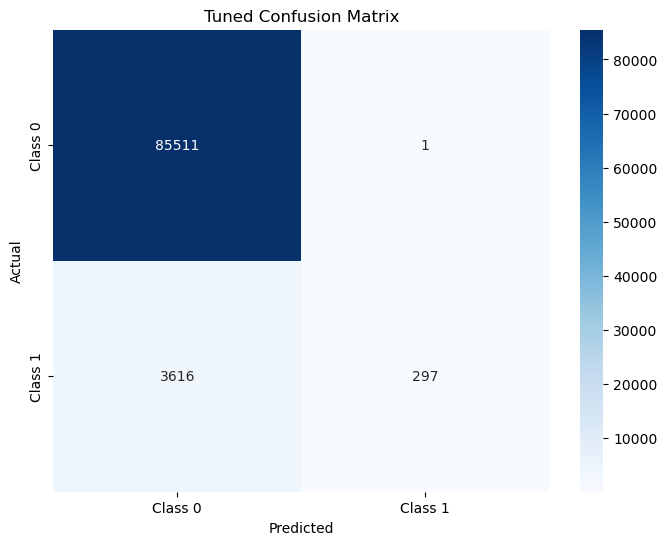

In [184]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Confusion Matrix')
plt.show()

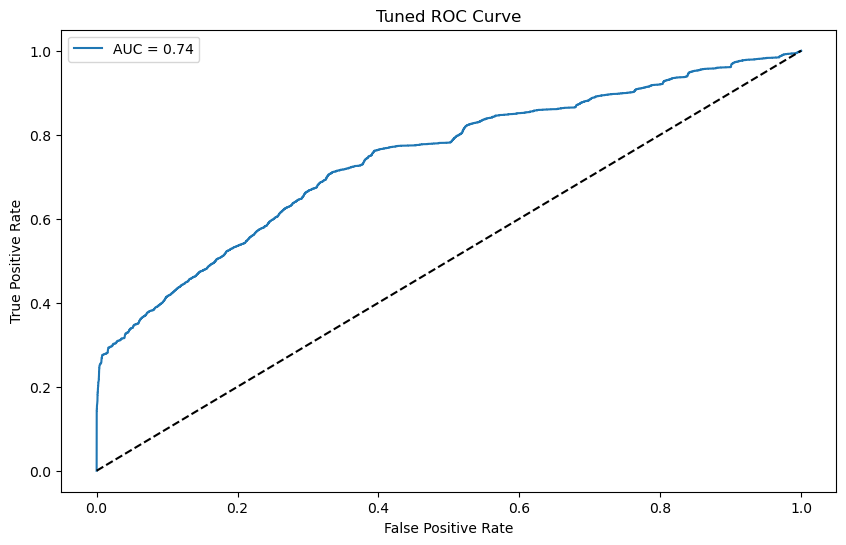

In [185]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc_roc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned ROC Curve')
plt.legend()
plt.show()

### We identify patients who are at risk of poor treatment outcomes and patients with good outcomes.

In [187]:
# Identify patients at risk of poor outcomes
risk_threshold = 0.5  # You can adjust this threshold based on your business requirements
at_risk_patients_indices = y_prob >= risk_threshold

# Extract the at-risk patients information
at_risk_patients = X_test[at_risk_patients_indices]
at_risk_patients_info = pd.DataFrame(at_risk_patients, columns=X.columns)
at_risk_patients_info['Actual Outcome'] = y_test[at_risk_patients_indices].values
at_risk_patients_info['Predicted Outcome'] = y_pred[at_risk_patients_indices]
at_risk_patients_info['Prediction Probability'] = y_prob[at_risk_patients_indices]

print("Patients at Risk of Poor Outcomes:\n", at_risk_patients_info)

Patients at Risk of Poor Outcomes:
      Current Age  Age at ART Initiation  Days Of ARV Refill  \
0       0.475661              -0.308001           -1.717774   
1       0.789552               0.436844           -1.084162   
2      -0.387540               0.023041           -0.450549   
3      -1.172268              -1.466650           -1.717774   
4      -1.093795              -0.804565           -0.450549   
..           ...                    ...                 ...   
293     2.123590               1.429972           -1.084162   
294    -0.152122              -0.970086           -1.717774   
295    -0.936850              -0.639044           -0.450549   
296     0.083297               0.023041           -1.717774   
297     0.475661               0.023041           -1.084162   

     Current Viral Load       Sex  Last Regimen  Actual Outcome  \
0              0.442725 -0.828462     -2.640689               1   
1              0.290542 -0.828462      0.376112               1   
2     

In [188]:
# Identify patients with good outcomes
good_outcome_threshold = 0.5  # You can adjust this threshold based on your business requirements
good_outcome_patients_indices = y_prob < good_outcome_threshold

# Extract the good outcome patients information
good_outcome_patients = X_test[good_outcome_patients_indices]
good_outcome_patients_info = pd.DataFrame(good_outcome_patients, columns=X.columns)
good_outcome_patients_info['Actual Outcome'] = y_test[good_outcome_patients_indices].values
good_outcome_patients_info['Predicted Outcome'] = y_pred[good_outcome_patients_indices]
good_outcome_patients_info['Prediction Probability'] = y_prob[good_outcome_patients_indices]

print("Patients with Good Outcomes:\n", good_outcome_patients_info)

Patients with Good Outcomes:
        Current Age  Age at ART Initiation  Days Of ARV Refill  \
0        -1.172268              -1.135607           -0.450549   
1         0.632607              -0.225241           -0.450549   
2        -0.622958              -0.556283           -0.450549   
3        -0.858377              -0.639044            1.450288   
4        -2.741725              -2.625298           -0.450549   
...            ...                    ...                 ...   
89122    -0.073649              -0.970086            1.450288   
89123    -1.015323              -0.804565           -0.450549   
89124     0.083297              -0.142480           -0.450549   
89125    -2.506306              -2.542538           -0.450549   
89126    -1.250741              -1.218368            1.450288   

       Current Viral Load       Sex  Last Regimen  Actual Outcome  \
0               -0.004685 -0.828462      0.074432               0   
1               -0.004428 -0.828462     -0.830608  

### We identify factors that are most predictive of successful or unsuccessful treatment.


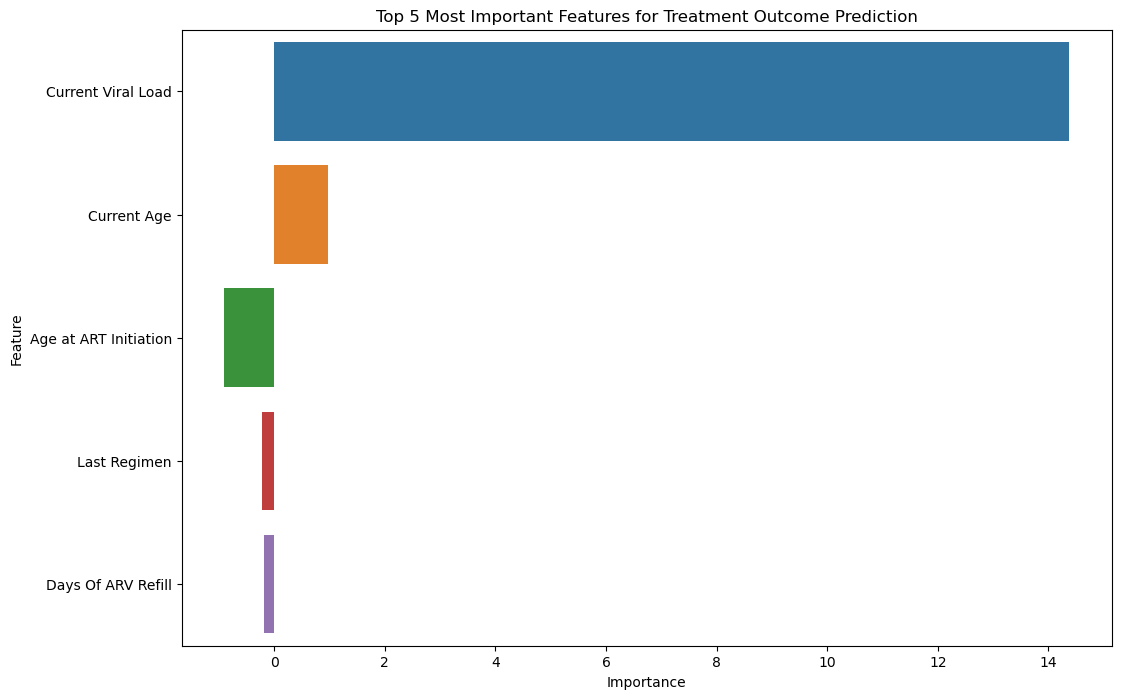

Top 5 Most Important Features:
                  Feature     Importance
3     Current Viral Load  230677.285808
0            Current Age       2.506324
1  Age at ART Initiation       0.211620
4                    Sex      -0.011272
5           Last Regimen      -2.288376


In [190]:
# Identify the most predictive factors
coefficients = best_lr_model.coef_[0]
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': coefficients
})

# Sort the DataFrame by importance
feature_importance = feature_importance.reindex(feature_importance['Importance'].abs().sort_values(ascending=False).index)

# Visualize the top 5 features
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(5))
plt.title('Top 5 Most Important Features for Treatment Outcome Prediction')
plt.show()

# Print the top 5 features
print("Top 5 Most Important Features:\n", feature_importance_df.head(5))

### //end of adapted code